# CIS 631 — Iron Deficiency Without Anemia: Machine Learning Analysis

**Project overview:** This notebook investigates whether iron deficiency without anemia can be predicted using demographic, dietary, lifestyle, and reproductive factors from the National Health and Nutrition Examination Survey (NHANES).

**Dataset:** The final analytic sample includes 2,397 nonpregnant women ages 20–44, with 27 non-laboratory predictors.

**Training and evaluation:** Models were developed using 1,455 participants from the 2009–2010 and 2015–2016 NHANES cycles and evaluated using 942 participants from the 2017–March 2020 cycle.

**Models evaluated:** Logistic regression, random forest, histogram gradient boosting, decision tree, K-nearest neighbors, and support vector machine.

**Validation:** The original model comparison used repeated cross-validation and hyperparameter tuning. Three additional models were subsequently evaluated using a shorter five-fold cross-validation procedure. Earlier random train-test splits are retained as exploratory history and should not be confused with the final cycle-based evaluation.

**Results:** All six models were evaluated using actual NHANES participant data. Logistic regression achieved the highest AUROC and average precision among the six non-laboratory models on the later-cycle evaluation set, although overall predictive performance remained limited.

**Limitations:** Because the later NHANES cycle appeared in earlier exploratory work, the evaluation should be described as retrospective cycle-based evaluation rather than completely independent external validation.

**Reproducibility:** Run the original data preparation cells before the modeling sections in a fresh Colab runtime. Model specifications, evaluation tables, and other outputs are saved in the `cis631_results/` directory, with additional outputs from the three-model extension.

In [ ]:
import pandas as pd
import requests
from io import BytesIO

In [ ]:
def load_xpt(url):
    response = requests.get(url)
    response.raise_for_status()
    return pd.read_sas(BytesIO(response.content), format="xport")

In [ ]:
demo = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/P_DEMO.XPT"
)

ferritin = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/P_FERTIN.XPT"
)

cbc = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/P_CBC.XPT"
)

diet = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/P_DR1TOT.XPT"
)

In [ ]:
print(demo.shape)
print(ferritin.shape)
print(cbc.shape)
print(diet.shape)

(15560, 29)
(11983, 3)
(13772, 22)
(14300, 168)


In [ ]:
demo.head()

,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,DMDBORN4,...,FIAINTRP,MIALANG,MIAPROXY,MIAINTRP,AIALANGA,WTINTPRP,WTMECPRP,SDMVPSU,SDMVSTRA,INDFMPIR
0,109263.0,66.0,2.0,1.0,2.0,NaN,5.0,6.0,2.0,1.0,...,2.0,NaN,NaN,NaN,NaN,7891.762435,8.951816e+03,3.0,156.0,4.66
1,109264.0,66.0,2.0,2.0,13.0,NaN,1.0,1.0,2.0,1.0,...,2.0,1.0,2.0,2.0,1.0,11689.747264,1.227116e+04,1.0,155.0,0.83
2,109265.0,66.0,2.0,1.0,2.0,NaN,3.0,3.0,2.0,1.0,...,2.0,NaN,NaN,NaN,NaN,16273.825939,1.665876e+04,1.0,157.0,3.06
3,109266.0,66.0,2.0,2.0,29.0,NaN,5.0,6.0,2.0,2.0,...,2.0,1.0,2.0,2.0,1.0,7825.646112,8.154968e+03,2.0,168.0,5.00
4,109267.0,66.0,1.0,2.0,21.0,NaN,2.0,2.0,NaN,2.0,...,2.0,NaN,NaN,NaN,NaN,26379.991724,5.397605e-79,1.0,156.0,5.00


In [ ]:
df = (
    demo
    .merge(ferritin, on="SEQN", how="inner")
    .merge(cbc, on="SEQN", how="inner")
    .merge(diet, on="SEQN", how="inner")
)

print(df.shape)

(11983, 219)


In [ ]:
df_women = df[
    (df["RIAGENDR"] == 2) &
    (df["RIDAGEYR"] >= 20) &
    (df["RIDAGEYR"] <= 44)
].copy()

print(df_women.shape)

(1750, 219)


In [ ]:
df_women["RIDEXPRG"].value_counts(dropna=False)

,count
RIDEXPRG,
2.0,1604
1.0,87
3.0,59


In [ ]:
df_nonpreg = df_women[
    df_women["RIDEXPRG"] == 2
].copy()

print(df_nonpreg.shape)

(1604, 219)


In [ ]:
print("Missing hemoglobin:", df_nonpreg["LBXHGB"].isna().sum())
print("Hemoglobin < 12.0:", (df_nonpreg["LBXHGB"] < 12.0).sum())

df_nonpreg["LBXHGB"].describe()

Missing hemoglobin: 61
Hemoglobin < 12.0: 239


,LBXHGB
count,1543.000000
mean,13.049968
std,1.325417
min,6.300000
25%,12.400000
50%,13.200000
75%,13.900000
max,17.200000


In [ ]:
df_nonanemic = df_nonpreg[
    (df_nonpreg["LBXHGB"].notna()) &
    (df_nonpreg["LBXHGB"] >= 12.0)
].copy()

print(df_nonanemic.shape)

(1304, 219)


In [ ]:
df_nonanemic["iron_deficient"] = (
    df_nonanemic["LBXFER"] < 15
).astype(int)

print(df_nonanemic["iron_deficient"].value_counts())
print(df_nonanemic["iron_deficient"].value_counts(normalize=True))

iron_deficient
0    1190
1     114
Name: count, dtype: int64
iron_deficient
0    0.912577
1    0.087423
Name: proportion, dtype: float64


In [ ]:
print("Missing ferritin:", df_nonanemic["LBXFER"].isna().sum())

Missing ferritin: 23


In [ ]:
df_1720 = df_nonanemic[
    df_nonanemic["LBXFER"].notna()
].copy()

df_1720["iron_deficient"] = (df_1720["LBXFER"] < 15).astype(int)

print(df_1720.shape)
print(df_1720["iron_deficient"].value_counts())

(1281, 220)
iron_deficient
0    1167
1     114
Name: count, dtype: int64


In [ ]:
demo15 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2015/DataFiles/DEMO_I.XPT"
)

ferritin15 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2015/DataFiles/FERTIN_I.XPT"
)

cbc15 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2015/DataFiles/CBC_I.XPT"
)

diet15 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2015/DataFiles/DR1TOT_I.XPT"
)

print(demo15.shape, ferritin15.shape, cbc15.shape, diet15.shape)

(9971, 47) (3252, 3) (9165, 21) (9544, 168)


In [ ]:
df15 = (
    demo15
    .merge(ferritin15, on="SEQN", how="inner")
    .merge(cbc15, on="SEQN", how="inner")
    .merge(diet15, on="SEQN", how="inner")
)

print(df15.shape)

(3252, 236)


In [ ]:
df15_women = df15[
    (df15["RIAGENDR"] == 2) &
    (df15["RIDAGEYR"] >= 20) &
    (df15["RIDAGEYR"] <= 44)
].copy()

print(df15_women.shape)

(1240, 236)


In [ ]:
df15_nonpreg = df15_women[
    df15_women["RIDEXPRG"] == 2
].copy()

print(df15_nonpreg.shape)

(1125, 236)


In [ ]:
df15_nonanemic = df15_nonpreg[
    (df15_nonpreg["LBXHGB"].notna()) &
    (df15_nonpreg["LBXHGB"] >= 12.0)
].copy()

print(df15_nonanemic.shape)

(891, 236)


In [ ]:
df15_clean = df15_nonanemic[
    df15_nonanemic["LBXFER"].notna()
].copy()

df15_clean["iron_deficient"] = (
    df15_clean["LBXFER"] < 15
).astype(int)

print(df15_clean.shape)
print(df15_clean["iron_deficient"].value_counts())
print(df15_clean["iron_deficient"].value_counts(normalize=True))

(888, 237)
iron_deficient
0    809
1     79
Name: count, dtype: int64
iron_deficient
0    0.911036
1    0.088964
Name: proportion, dtype: float64


In [ ]:
candidate_vars = [
    "SEQN",
    "RIDAGEYR",
    "DR1TIRON",
    "DR1TVC",
    "DR1TKCAL",
    "DR1TPROT",
    "DR1TFIBE",
    "DR1TCALC",
    "DR1TCAFF",
    "DR1TALCO",
    "iron_deficient"
]

for var in candidate_vars:
    print(
        var,
        "2015-16:", var in df15_clean.columns,
        "2017-20:", var in df_1720.columns
    )

SEQN 2015-16: True 2017-20: True
RIDAGEYR 2015-16: True 2017-20: True
DR1TIRON 2015-16: True 2017-20: True
DR1TVC 2015-16: True 2017-20: True
DR1TKCAL 2015-16: True 2017-20: True
DR1TPROT 2015-16: True 2017-20: True
DR1TFIBE 2015-16: True 2017-20: True
DR1TCALC 2015-16: True 2017-20: True
DR1TCAFF 2015-16: True 2017-20: True
DR1TALCO 2015-16: True 2017-20: True
iron_deficient 2015-16: True 2017-20: True


In [ ]:
train15 = df15_clean[candidate_vars].copy()
train1720 = df_1720[candidate_vars].copy()

train15["cycle"] = "2015-2016"
train1720["cycle"] = "2017-2020"

In [ ]:
train_combined = pd.concat(
    [train15, train1720],
    ignore_index=True
)

print(train_combined.shape)
print(train_combined["iron_deficient"].value_counts())

(2169, 12)
iron_deficient
0    1976
1     193
Name: count, dtype: int64


In [ ]:
rhq15 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2015/DataFiles/RHQ_I.XPT"
)

paq15 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2015/DataFiles/PAQ_I.XPT"
)

smq15 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2015/DataFiles/SMQ_I.XPT"
)

alq15 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2015/DataFiles/ALQ_I.XPT"
)

supp15 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2015/DataFiles/DSQTOT_I.XPT"
)

In [ ]:
rhq1720 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/P_RHQ.XPT"
)

paq1720 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/P_PAQ.XPT"
)

smq1720 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/P_SMQ.XPT"
)

alq1720 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/P_ALQ.XPT"
)

supp1720 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/P_DSQTOT.XPT"
)

In [ ]:
print("2015-16:")
print(rhq15.shape, paq15.shape, smq15.shape, alq15.shape, supp15.shape)

print("2017-20:")
print(rhq1720.shape, paq1720.shape, smq1720.shape, alq1720.shape, supp1720.shape)

2015-16:
(3471, 46) (9255, 94) (7001, 42) (5735, 10) (9971, 39)
2017-20:
(5314, 32) (9693, 17) (11137, 16) (8965, 10) (15560, 39)


In [ ]:
candidate_extra_vars = {
    "reproductive": [
        "RHQ031",   # period in past 12 months
        "RHD043",   # reason for no periods
        "RHQ200",   # breastfeeding
        "RHD280"    # hysterectomy
    ],

    "physical_activity": [
        "PAQ650",   # vigorous recreation
        "PAQ665",   # moderate recreation
        "PAD680"    # sedentary minutes/day
    ],

    "smoking": [
        "SMQ020",   # smoked 100 cigarettes lifetime
        "SMQ040"    # current smoking status
    ],

    "alcohol": [
        "ALQ111",
        "ALQ121",
        "ALQ130",
        "ALQ170"
    ],

    "supplements": [
        "DSD010",    # used supplements
        "DSDCOUNT",  # number of supplements
        "DSQTIRON",  # supplemental iron
        "DSQTVC",    # supplemental vitamin C
        "DSQTCALC"   # supplemental calcium
    ]
}

pairs = {
    "reproductive": (rhq15, rhq1720),
    "physical_activity": (paq15, paq1720),
    "smoking": (smq15, smq1720),
    "alcohol": (alq15, alq1720),
    "supplements": (supp15, supp1720)
}

for group, variables in candidate_extra_vars.items():
    print(f"\n{group.upper()}")

    df_old, df_new = pairs[group]

    for var in variables:
        print(
            var,
            "2015-16:", var in df_old.columns,
            "2017-20:", var in df_new.columns
        )


REPRODUCTIVE
RHQ031 2015-16: True 2017-20: True
RHD043 2015-16: True 2017-20: True
RHQ200 2015-16: True 2017-20: True
RHD280 2015-16: True 2017-20: True

PHYSICAL_ACTIVITY
PAQ650 2015-16: True 2017-20: True
PAQ665 2015-16: True 2017-20: True
PAD680 2015-16: True 2017-20: True

SMOKING
SMQ020 2015-16: True 2017-20: True
SMQ040 2015-16: True 2017-20: True

ALCOHOL
ALQ111 2015-16: False 2017-20: True
ALQ121 2015-16: False 2017-20: True
ALQ130 2015-16: True 2017-20: True
ALQ170 2015-16: False 2017-20: True

SUPPLEMENTS
DSD010 2015-16: True 2017-20: True
DSDCOUNT 2015-16: True 2017-20: True
DSQTIRON 2015-16: True 2017-20: True
DSQTVC 2015-16: True 2017-20: True
DSQTCALC 2015-16: True 2017-20: True


In [ ]:
extra_vars = [
    # Reproductive
    "RHQ031",
    "RHQ200",
    "RHD280",

    # Physical activity
    "PAQ650",
    "PAQ665",
    "PAD680",

    # Smoking
    "SMQ020",
    "SMQ040",

    # Alcohol
    "ALQ130",

    # Supplements
    "DSD010",
    "DSDCOUNT",
    "DSQTIRON",
    "DSQTVC",
    "DSQTCALC"
]

In [ ]:
extra15 = (
    rhq15[["SEQN", "RHQ031", "RHQ200", "RHD280"]]
    .merge(paq15[["SEQN", "PAQ650", "PAQ665", "PAD680"]], on="SEQN", how="outer")
    .merge(smq15[["SEQN", "SMQ020", "SMQ040"]], on="SEQN", how="outer")
    .merge(alq15[["SEQN", "ALQ130"]], on="SEQN", how="outer")
    .merge(
        supp15[["SEQN", "DSD010", "DSDCOUNT", "DSQTIRON", "DSQTVC", "DSQTCALC"]],
        on="SEQN",
        how="outer"
    )
)

train15_full = train15.merge(extra15, on="SEQN", how="left")

In [ ]:
extra1720 = (
    rhq1720[["SEQN", "RHQ031", "RHQ200", "RHD280"]]
    .merge(paq1720[["SEQN", "PAQ650", "PAQ665", "PAD680"]], on="SEQN", how="outer")
    .merge(smq1720[["SEQN", "SMQ020", "SMQ040"]], on="SEQN", how="outer")
    .merge(alq1720[["SEQN", "ALQ130"]], on="SEQN", how="outer")
    .merge(
        supp1720[["SEQN", "DSD010", "DSDCOUNT", "DSQTIRON", "DSQTVC", "DSQTCALC"]],
        on="SEQN",
        how="outer"
    )
)

train1720_full = train1720.merge(extra1720, on="SEQN", how="left")

In [ ]:
train_combined = pd.concat(
    [train15_full, train1720_full],
    ignore_index=True
)

print(train_combined.shape)

(2169, 26)


In [ ]:
missing = train_combined.isna().sum().sort_values(ascending=False)

print(missing)

RHQ200            1884
DSQTIRON          1776
SMQ040            1547
DSQTCALC          1465
DSQTVC            1462
ALQ130             615
RHD280             243
RHQ031             225
DR1TVC             186
DR1TIRON           186
DR1TPROT           186
DR1TKCAL           186
DR1TALCO           186
DR1TCAFF           186
DR1TCALC           186
DR1TFIBE           186
PAD680               2
RIDAGEYR             0
SEQN                 0
PAQ650               0
cycle                0
iron_deficient       0
PAQ665               0
SMQ020               0
DSD010               0
DSDCOUNT             0
dtype: int64


In [ ]:
missing_pct = (
    train_combined.isna().mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(missing_pct)

RHQ200            86.860304
DSQTIRON          81.881051
SMQ040            71.323190
DSQTCALC          67.542646
DSQTVC            67.404334
ALQ130            28.354080
RHD280            11.203320
RHQ031            10.373444
DR1TVC             8.575380
DR1TIRON           8.575380
DR1TPROT           8.575380
DR1TKCAL           8.575380
DR1TALCO           8.575380
DR1TCAFF           8.575380
DR1TCALC           8.575380
DR1TFIBE           8.575380
PAD680             0.092208
RIDAGEYR           0.000000
SEQN               0.000000
PAQ650             0.000000
cycle              0.000000
iron_deficient     0.000000
PAQ665             0.000000
SMQ020             0.000000
DSD010             0.000000
DSDCOUNT           0.000000
dtype: float64


In [ ]:
# Drop variables we do not want in the first baseline
train_combined = train_combined.drop(
    columns=["RHQ200", "ALQ130"]
)

# Nutrient intake from supplements:
# no reported amount -> 0 mg/day
for col in ["DSQTIRON", "DSQTVC", "DSQTCALC"]:
    train_combined[col] = train_combined[col].fillna(0)

In [ ]:
import numpy as np

def smoking_status(row):
    # Never smoked 100 cigarettes
    if row["SMQ020"] == 2:
        return "never"

    # Smoked 100+ cigarettes and currently smokes
    if row["SMQ020"] == 1 and row["SMQ040"] in [1, 2]:
        return "current"

    # Smoked 100+ cigarettes but not currently
    if row["SMQ020"] == 1 and row["SMQ040"] == 3:
        return "former"

    return np.nan

train_combined["smoking_status"] = train_combined.apply(
    smoking_status,
    axis=1
)

train_combined = train_combined.drop(
    columns=["SMQ020", "SMQ040"]
)

In [ ]:
(train_combined.isna().mean() * 100).sort_values(ascending=False)

,0
RHD280,11.203320
RHQ031,10.373444
DR1TIRON,8.575380
DR1TPROT,8.575380
DR1TFIBE,8.575380
DR1TKCAL,8.575380
DR1TVC,8.575380
DR1TALCO,8.575380
DR1TCAFF,8.575380
DR1TCALC,8.575380


In [ ]:
categorical_check = [
    "RHD280",
    "RHQ031",
    "PAQ650",
    "PAQ665",
    "DSD010",
    "smoking_status"
]

for col in categorical_check:
    print(f"\n{col}")
    print(train_combined[col].value_counts(dropna=False).sort_index())


RHD280
RHD280
1.0      86
2.0    1840
NaN     243
Name: count, dtype: int64

RHQ031
RHQ031
1.0    1728
2.0     216
NaN     225
Name: count, dtype: int64

PAQ650
PAQ650
1.0     726
2.0    1443
Name: count, dtype: int64

PAQ665
PAQ665
1.0    1041
2.0    1128
Name: count, dtype: int64

DSD010
DSD010
1.0    1054
2.0    1115
Name: count, dtype: int64

smoking_status
smoking_status
current     372
former      250
never      1545
NaN           2
Name: count, dtype: int64


In [ ]:
numeric_features = [
    "RIDAGEYR",
    "DR1TIRON",
    "DR1TVC",
    "DR1TKCAL",
    "DR1TPROT",
    "DR1TFIBE",
    "DR1TCALC",
    "DR1TCAFF",
    "DR1TALCO",
    "PAD680",
    "DSDCOUNT",
    "DSQTIRON",
    "DSQTVC",
    "DSQTCALC"
]

categorical_features = [
    "RHD280",
    "RHQ031",
    "PAQ650",
    "PAQ665",
    "DSD010",
    "smoking_status"
]

X = train_combined[numeric_features + categorical_features].copy()
y = train_combined["iron_deficient"].copy()

print(X.shape)
print(y.value_counts())

(2169, 20)
iron_deficient
0    1976
1     193
Name: count, dtype: int64


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", y_train.value_counts())
print("Testing:", y_test.value_counts())

Training: iron_deficient
0    1581
1     154
Name: count, dtype: int64
Testing: iron_deficient
0    395
1     39
Name: count, dtype: int64


In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline

dummy_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DummyClassifier(strategy="most_frequent"))
])

dummy_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['RIDAGEYR', 'DR1TIRON',
                                                   'DR1TVC', 'DR1TKCAL',
                                                   'DR1TPROT', 'DR1TFIBE',
                                                   'DR1TCALC', 'DR1TCAFF',
                                                   'DR1TALCO', 'PAD680',
                                                   'DSDCOUNT', 'DSQTIRON',
                                                   'DSQTVC', 'DSQTCALC']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['RHD280', 'RHQ031', 'PAQ650',
                                                   'PAQ665', 'DSD010',
                                                   'smoking_status'])])),
                ('classifier', DummyClassifier(strategy='most_frequent'))])

In [ ]:
y_pred_dummy = dummy_model.predict(X_test)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred_dummy))
print("Precision:", precision_score(y_test, y_pred_dummy, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_dummy, zero_division=0))
print("F1:", f1_score(y_test, y_pred_dummy, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dummy))

Accuracy: 0.9101382488479263
Precision: 0.0
Recall: 0.0
F1: 0.0

Confusion Matrix:
[[395   0]
 [ 39   0]]


In [ ]:
from sklearn.linear_model import LogisticRegression

logreg_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

logreg_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['RIDAGEYR', 'DR1TIRON',
                                                   'DR1TVC', 'DR1TKCAL',
                                                   'DR1TPROT', 'DR1TFIBE',
                                                   'DR1TCALC', 'DR1TCAFF',
                                                   'DR1TALCO', 'PAD680',
                                                   'DSDCOUNT', 'DSQTIRON',
                                                   'DSQTVC', 'DSQTCALC']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['RHD280', 'RHQ031', 'PAQ650',
                                                   'PAQ665', 'DSD010',
                                                   'smoking_status'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [ ]:
y_pred_logreg = logreg_model.predict(X_test)
y_prob_logreg = logreg_model.predict_proba(X_test)[:, 1]

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred_logreg))
print("Precision:", precision_score(y_test, y_pred_logreg))
print("Recall:", recall_score(y_test, y_pred_logreg))
print("F1:", f1_score(y_test, y_pred_logreg))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_logreg))
print("PR-AUC:", average_precision_score(y_test, y_prob_logreg))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_logreg))

Accuracy: 0.4815668202764977
Precision: 0.09565217391304348
Recall: 0.5641025641025641
F1: 0.16356877323420074
ROC-AUC: 0.5289191820837391
PR-AUC: 0.09303422319615089

Confusion Matrix:
[[187 208]
 [ 17  22]]


In [ ]:
demo09 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2009/DataFiles/DEMO_F.XPT"
)

ferritin09 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2009/DataFiles/FERTIN_F.XPT"
)

cbc09 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2009/DataFiles/CBC_F.XPT"
)

diet09 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2009/DataFiles/DR1TOT_F.XPT"
)

print(demo09.shape, ferritin09.shape, cbc09.shape, diet09.shape)

(10537, 43) (3521, 3) (9835, 21) (10253, 166)


In [ ]:
df09 = (
    demo09
    .merge(ferritin09, on="SEQN", how="inner")
    .merge(cbc09, on="SEQN", how="inner")
    .merge(diet09, on="SEQN", how="inner")
)

print(df09.shape)

(3521, 230)


In [ ]:
df09_women = df09[
    (df09["RIAGENDR"] == 2) &
    (df09["RIDAGEYR"] >= 20) &
    (df09["RIDAGEYR"] <= 44)
].copy()

print(df09_women.shape)

(1377, 230)


In [ ]:
df09_nonpreg = df09_women[
    df09_women["RIDEXPRG"] == 2
].copy()

print(df09_nonpreg.shape)

(1266, 230)


In [ ]:
df09_nonanemic = df09_nonpreg[
    (df09_nonpreg["LBXHGB"].notna()) &
    (df09_nonpreg["LBXHGB"] >= 12.0)
].copy()

print(df09_nonanemic.shape)

(1083, 230)


In [ ]:
df09_clean = df09_nonanemic[
    df09_nonanemic["LBXFER"].notna()
].copy()

df09_clean["iron_deficient"] = (
    df09_clean["LBXFER"] < 15
).astype(int)

print(df09_clean.shape)
print(df09_clean["iron_deficient"].value_counts())
print(df09_clean["iron_deficient"].value_counts(normalize=True))

(1072, 231)
iron_deficient
0    950
1    122
Name: count, dtype: int64
iron_deficient
0    0.886194
1    0.113806
Name: proportion, dtype: float64


In [ ]:
rhq09 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2009/DataFiles/RHQ_F.XPT"
)

paq09 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2009/DataFiles/PAQ_F.XPT"
)

smq09 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2009/DataFiles/SMQ_F.XPT"
)

alq09 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2009/DataFiles/ALQ_F.XPT"
)

supp09 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2009/DataFiles/DSQTOT_F.XPT"
)

In [ ]:
candidate_extra_vars = {
    "reproductive": [
        "RHQ031",
        "RHD280"
    ],

    "physical_activity": [
        "PAQ650",
        "PAQ665",
        "PAD680"
    ],

    "smoking": [
        "SMQ020",
        "SMQ040"
    ],

    "supplements": [
        "DSD010",
        "DSDCOUNT",
        "DSQTIRON",
        "DSQTVC",
        "DSQTCALC"
    ]
}

pairs09 = {
    "reproductive": rhq09,
    "physical_activity": paq09,
    "smoking": smq09,
    "supplements": supp09
}

for group, variables in candidate_extra_vars.items():
    print(f"\n{group.upper()}")

    df_group = pairs09[group]

    for var in variables:
        print(
            var,
            "2009-10:", var in df_group.columns
        )


REPRODUCTIVE
RHQ031 2009-10: True
RHD280 2009-10: True

PHYSICAL_ACTIVITY
PAQ650 2009-10: True
PAQ665 2009-10: True
PAD680 2009-10: True

SMOKING
SMQ020 2009-10: True
SMQ040 2009-10: True

SUPPLEMENTS
DSD010 2009-10: True
DSDCOUNT 2009-10: True
DSQTIRON 2009-10: True
DSQTVC 2009-10: True
DSQTCALC 2009-10: True


In [ ]:
diet_vars = [
    "DR1TIRON",
    "DR1TVC",
    "DR1TKCAL",
    "DR1TPROT",
    "DR1TFIBE",
    "DR1TCALC",
    "DR1TCAFF",
    "DR1TALCO"
]

for var in diet_vars:
    print(var, "2009-10:", var in df09_clean.columns)

DR1TIRON 2009-10: True
DR1TVC 2009-10: True
DR1TKCAL 2009-10: True
DR1TPROT 2009-10: True
DR1TFIBE 2009-10: True
DR1TCALC 2009-10: True
DR1TCAFF 2009-10: True
DR1TALCO 2009-10: True


In [ ]:
base_vars = [
    "SEQN",
    "RIDAGEYR",
    "DR1TIRON",
    "DR1TVC",
    "DR1TKCAL",
    "DR1TPROT",
    "DR1TFIBE",
    "DR1TCALC",
    "DR1TCAFF",
    "DR1TALCO",
    "iron_deficient"
]

train09 = df09_clean[base_vars].copy()
train09["cycle"] = "2009-2010"

In [ ]:
extra09 = (
    rhq09[["SEQN", "RHQ031", "RHD280"]]
    .merge(paq09[["SEQN", "PAQ650", "PAQ665", "PAD680"]], on="SEQN", how="outer")
    .merge(smq09[["SEQN", "SMQ020", "SMQ040"]], on="SEQN", how="outer")
    .merge(
        supp09[
            ["SEQN", "DSD010", "DSDCOUNT", "DSQTIRON", "DSQTVC", "DSQTCALC"]
        ],
        on="SEQN",
        how="outer"
    )
)

In [ ]:
train09_full = train09.merge(
    extra09,
    on="SEQN",
    how="left"
)

In [ ]:
# Supplement amounts: no reported amount -> 0
for col in ["DSQTIRON", "DSQTVC", "DSQTCALC"]:
    train09_full[col] = train09_full[col].fillna(0)

In [ ]:
import numpy as np

def smoking_status(row):
    if row["SMQ020"] == 2:
        return "never"

    if row["SMQ020"] == 1 and row["SMQ040"] in [1, 2]:
        return "current"

    if row["SMQ020"] == 1 and row["SMQ040"] == 3:
        return "former"

    return np.nan

train09_full["smoking_status"] = train09_full.apply(
    smoking_status,
    axis=1
)

train09_full = train09_full.drop(
    columns=["SMQ020", "SMQ040"]
)

In [ ]:
print(train09_full.shape)
print(train09_full["iron_deficient"].value_counts())

(1072, 23)
iron_deficient
0    950
1    122
Name: count, dtype: int64


In [ ]:
train_combined_expanded = pd.concat(
    [train09_full, train_combined],
    ignore_index=True
)

print(train_combined_expanded.shape)
print(train_combined_expanded["iron_deficient"].value_counts())
print(train_combined_expanded["iron_deficient"].value_counts(normalize=True))

(3241, 23)
iron_deficient
0    2926
1     315
Name: count, dtype: int64
iron_deficient
0    0.902808
1    0.097192
Name: proportion, dtype: float64


In [ ]:
X = train_combined_expanded[
    numeric_features + categorical_features
].copy()

y = train_combined_expanded["iron_deficient"].copy()

print(X.shape)
print(y.value_counts())

(3241, 20)
iron_deficient
0    2926
1     315
Name: count, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:")
print(y_train.value_counts())

print("\nTesting:")
print(y_test.value_counts())

Training:
iron_deficient
0    2340
1     252
Name: count, dtype: int64

Testing:
iron_deficient
0    586
1     63
Name: count, dtype: int64


In [ ]:
logreg_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

logreg_model.fit(X_train, y_train)

y_pred_logreg = logreg_model.predict(X_test)
y_prob_logreg = logreg_model.predict_proba(X_test)[:, 1]

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred_logreg))
print("Precision:", precision_score(y_test, y_pred_logreg))
print("Recall:", recall_score(y_test, y_pred_logreg))
print("F1:", f1_score(y_test, y_pred_logreg))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_logreg))
print("PR-AUC:", average_precision_score(y_test, y_prob_logreg))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_logreg))

Accuracy: 0.4067796610169492
Precision: 0.08928571428571429
Recall: 0.5555555555555556
F1: 0.15384615384615385
ROC-AUC: 0.5135435289018906
PR-AUC: 0.11347050621039087

Confusion Matrix:
[[229 357]
 [ 28  35]]


Age restriction: The study population is restricted to women ages 20-44 because NHANES publicly releases the examination-based pregnancy status variable RIDEXPRG only for females ages 20-44. Although the originally proposed population included women ages 18-49, restricting the cohort to ages 20-44 allows pregnancy status to be determined consistently across all included NHANES cycles.

In [ ]:
import pandas as pd
import requests
from io import BytesIO

def load_xpt(url):
    response = requests.get(url)
    response.raise_for_status()
    return pd.read_sas(BytesIO(response.content), format="xport")

In [ ]:
# 2009-2010 CRP
crp09 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2009/DataFiles/CRP_F.XPT"
)

# 2015-2016 high-sensitivity CRP
crp15 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2015/DataFiles/HSCRP_I.XPT"
)

# 2017-March 2020 high-sensitivity CRP
crp17 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/P_HSCRP.XPT"
)

print("2009-2010:", crp09.shape, crp09.columns.tolist())
print("2015-2016:", crp15.shape, crp15.columns.tolist())
print("2017-2020:", crp17.shape, crp17.columns.tolist())

2009-2010: (9211, 2) ['SEQN', 'LBXCRP']
2015-2016: (9165, 3) ['SEQN', 'LBXHSCRP', 'LBDHRPLC']
2017-2020: (13772, 3) ['SEQN', 'LBXHSCRP', 'LBDHRPLC']


In [ ]:
# Harmonize CRP to mg/L

crp09_clean = crp09[["SEQN", "LBXCRP"]].copy()
crp09_clean["CRP_mgL"] = crp09_clean["LBXCRP"] * 10
crp09_clean = crp09_clean[["SEQN", "CRP_mgL"]]

crp15_clean = crp15[["SEQN", "LBXHSCRP"]].copy()
crp15_clean["CRP_mgL"] = crp15_clean["LBXHSCRP"]
crp15_clean = crp15_clean[["SEQN", "CRP_mgL"]]

crp17_clean = crp17[["SEQN", "LBXHSCRP"]].copy()
crp17_clean["CRP_mgL"] = crp17_clean["LBXHSCRP"]
crp17_clean = crp17_clean[["SEQN", "CRP_mgL"]]

In [ ]:
print("2009-2010")
print(crp09_clean["CRP_mgL"].describe())

print("\n2015-2016")
print(crp15_clean["CRP_mgL"].describe())

print("\n2017-2020")
print(crp17_clean["CRP_mgL"].describe())

2009-2010
count    8299.000000
mean        3.387878
std         7.137068
min         0.100000
25%         0.400000
50%         1.300000
75%         3.500000
max       180.100000
Name: CRP_mgL, dtype: float64

2015-2016
count    7867.000000
mean        3.411364
std         7.515623
min         0.080000
25%         0.400000
50%         1.200000
75%         3.600000
max       188.500000
Name: CRP_mgL, dtype: float64

2017-2020
count    11614.000000
mean         3.422093
std          7.792654
min          0.110000
25%          0.520000
50%          1.320000
75%          3.620000
max        246.860000
Name: CRP_mgL, dtype: float64


In [ ]:
crp09_clean["cycle"] = "2009-2010"
crp15_clean["cycle"] = "2015-2016"
crp17_clean["cycle"] = "2017-2020"

crp_all = pd.concat(
    [crp09_clean, crp15_clean, crp17_clean],
    ignore_index=True
)

print(crp_all.shape)

(32148, 3)


In [ ]:
print(train_combined_expanded.shape)

(3241, 23)


In [ ]:
train_with_crp = train_combined_expanded.merge(
    crp_all,
    on=["SEQN", "cycle"],
    how="left"
)

print(train_with_crp.shape)

(3241, 24)


In [ ]:
print("Missing CRP:")
print(train_with_crp["CRP_mgL"].isna().sum())

print("\nCRP > 5 mg/L:")
print((train_with_crp["CRP_mgL"] > 5).sum())

print("\nPercent > 5 mg/L:")
print((train_with_crp["CRP_mgL"] > 5).mean() * 100)

print("\nIron deficiency vs elevated CRP:")
print(
    pd.crosstab(
        train_with_crp["iron_deficient"],
        train_with_crp["CRP_mgL"] > 5
    )
)

Missing CRP:
17

CRP > 5 mg/L:
807

Percent > 5 mg/L:
24.89972230792965

Iron deficiency vs elevated CRP:
CRP_mgL         False  True 
iron_deficient              
0                2165    761
1                 269     46


In [ ]:
print(
    train_with_crp.loc[
        train_with_crp["CRP_mgL"].isna(),
        ["cycle", "iron_deficient"]
    ].value_counts()
)

cycle      iron_deficient
2017-2020  0                 12
2015-2016  0                  4
2017-2020  1                  1
Name: count, dtype: int64


In [ ]:
print(
    pd.crosstab(
        train_with_crp["cycle"],
        train_with_crp["CRP_mgL"] > 5
    )
)

CRP_mgL    False  True 
cycle                  
2009-2010    800    272
2015-2016    667    221
2017-2020    967    314


In [ ]:
train_inflammation_clean = train_with_crp[
    train_with_crp["CRP_mgL"].notna() &
    (train_with_crp["CRP_mgL"] <= 5)
].copy()

print("New sample size:", train_inflammation_clean.shape)

print("\nIron deficiency counts:")
print(train_inflammation_clean["iron_deficient"].value_counts())

print("\nIron deficiency prevalence:")
print(
    train_inflammation_clean["iron_deficient"]
    .value_counts(normalize=True)
)

New sample size: (2417, 24)

Iron deficiency counts:
iron_deficient
0    2149
1     268
Name: count, dtype: int64

Iron deficiency prevalence:
iron_deficient
0    0.889119
1    0.110881
Name: proportion, dtype: float64


In [ ]:
print("LBXFER" in train_inflammation_clean.columns)

False


In [ ]:
[name for name in globals() if "ferr" in name.lower()]

['ferritin', 'ferritin15', 'ferritin09']

In [ ]:
ferritin09_keep = ferritin09[["SEQN", "LBXFER"]].copy()
ferritin09_keep["cycle"] = "2009-2010"

ferritin15_keep = ferritin15[["SEQN", "LBXFER"]].copy()
ferritin15_keep["cycle"] = "2015-2016"

ferritin17_keep = ferritin[["SEQN", "LBXFER"]].copy()
ferritin17_keep["cycle"] = "2017-2020"

ferritin_all = pd.concat(
    [ferritin09_keep, ferritin15_keep, ferritin17_keep],
    ignore_index=True
)

In [ ]:
train_inflammation_clean = train_inflammation_clean.merge(
    ferritin_all,
    on=["SEQN", "cycle"],
    how="left"
)

print(train_inflammation_clean["LBXFER"].isna().sum())
print(train_inflammation_clean[["LBXFER", "iron_deficient"]].head())

0
   LBXFER  iron_deficient
0     7.0               1
1    34.0               0
2    40.0               0
3    32.0               0
4    70.0               0


In [ ]:
check_target = (
    (train_inflammation_clean["LBXFER"] < 15).astype(int)
    == train_inflammation_clean["iron_deficient"]
)

print(check_target.value_counts())

True    2417
Name: count, dtype: int64


In [ ]:
train_inflammation_clean["iron_deficient_30"] = (
    train_inflammation_clean["LBXFER"] < 30
).astype(int)

print("Primary outcome: ferritin < 15")
print(train_inflammation_clean["iron_deficient"].value_counts())
print(
    train_inflammation_clean["iron_deficient"]
    .value_counts(normalize=True)
)

print("\nSensitivity outcome: ferritin < 30")
print(train_inflammation_clean["iron_deficient_30"].value_counts())
print(
    train_inflammation_clean["iron_deficient_30"]
    .value_counts(normalize=True)
)

Primary outcome: ferritin < 15
iron_deficient
0    2149
1     268
Name: count, dtype: int64
iron_deficient
0    0.889119
1    0.110881
Name: proportion, dtype: float64

Sensitivity outcome: ferritin < 30
iron_deficient_30
0    1605
1     812
Name: count, dtype: int64
iron_deficient_30
0    0.664046
1    0.335954
Name: proportion, dtype: float64


In [ ]:
print([name for name in globals() if "cbc" in name.lower()])
print([name for name in globals() if "smq" in name.lower()])

['cbc', 'cbc15', 'cbc09']
['smq15', 'smq1720', 'smq09']


In [ ]:
for name, df in [
    ("CBC 2009-2010", cbc09),
    ("CBC 2015-2016", cbc15),
    ("CBC 2017-2020", cbc)
]:
    print(name, "LBXHGB:", "LBXHGB" in df.columns)

print()

for name, df in [
    ("SMQ 2009-2010", smq09),
    ("SMQ 2015-2016", smq15),
    ("SMQ 2017-2020", smq1720)
]:
    print(name, "SMD650:", "SMD650" in df.columns)

CBC 2009-2010 LBXHGB: True
CBC 2015-2016 LBXHGB: True
CBC 2017-2020 LBXHGB: True

SMQ 2009-2010 SMD650: True
SMQ 2015-2016 SMD650: True
SMQ 2017-2020 SMD650: True


In [ ]:
hgb09 = cbc09[["SEQN", "LBXHGB"]].copy()
hgb09["cycle"] = "2009-2010"

hgb15 = cbc15[["SEQN", "LBXHGB"]].copy()
hgb15["cycle"] = "2015-2016"

hgb17 = cbc[["SEQN", "LBXHGB"]].copy()
hgb17["cycle"] = "2017-2020"

hgb_all = pd.concat(
    [hgb09, hgb15, hgb17],
    ignore_index=True
)

In [ ]:
smoke09 = smq09[["SEQN", "SMD650"]].copy()
smoke09["cycle"] = "2009-2010"

smoke15 = smq15[["SEQN", "SMD650"]].copy()
smoke15["cycle"] = "2015-2016"

smoke17 = smq1720[["SEQN", "SMD650"]].copy()
smoke17["cycle"] = "2017-2020"

smoke_all = pd.concat(
    [smoke09, smoke15, smoke17],
    ignore_index=True
)

In [ ]:
train_inflammation_clean = (
    train_inflammation_clean
    .merge(hgb_all, on=["SEQN", "cycle"], how="left")
    .merge(smoke_all, on=["SEQN", "cycle"], how="left")
)

In [ ]:
print("Missing hemoglobin:", train_inflammation_clean["LBXHGB"].isna().sum())

print("\nCigarettes/day:")
print(train_inflammation_clean["SMD650"].describe())

print("\nUnique smoking quantities:")
print(
    train_inflammation_clean["SMD650"]
    .value_counts()
    .sort_index()
)

Missing hemoglobin: 0

Cigarettes/day:
count    474.000000
mean      11.689873
std       46.043261
min        1.000000
25%        4.000000
50%        8.000000
75%       12.000000
max      999.000000
Name: SMD650, dtype: float64

Unique smoking quantities:
SMD650
1.0       41
2.0       29
3.0       31
4.0       32
5.0       45
6.0       29
7.0       17
8.0       17
9.0        2
10.0     103
11.0       3
12.0       8
13.0       3
15.0      17
17.0       2
18.0       1
20.0      78
25.0       2
30.0       8
35.0       1
40.0       4
999.0      1
Name: count, dtype: int64


In [ ]:
# Clean special NHANES smoking codes
train_inflammation_clean["SMD650_clean"] = (
    train_inflammation_clean["SMD650"]
    .replace([777, 999], np.nan)
)

# Start with no adjustment
train_inflammation_clean["smoking_hgb_adjustment"] = 0.0

current = train_inflammation_clean["smoking_status"] == "current"
cigs = train_inflammation_clean["SMD650_clean"]

# Current smoker, quantity unknown: subtract 0.3 g/dL
train_inflammation_clean.loc[
    current & cigs.isna(),
    "smoking_hgb_adjustment"
] = 0.3

# <10 cigarettes/day: subtract 0.3 g/dL
train_inflammation_clean.loc[
    current & (cigs < 10),
    "smoking_hgb_adjustment"
] = 0.3

# 10-19 cigarettes/day: subtract 0.5 g/dL
train_inflammation_clean.loc[
    current & (cigs >= 10) & (cigs <= 19),
    "smoking_hgb_adjustment"
] = 0.5

# 20+ cigarettes/day: subtract 0.6 g/dL
train_inflammation_clean.loc[
    current & (cigs >= 20),
    "smoking_hgb_adjustment"
] = 0.6

# Smoking-adjusted hemoglobin
train_inflammation_clean["LBXHGB_adjusted"] = (
    train_inflammation_clean["LBXHGB"]
    - train_inflammation_clean["smoking_hgb_adjustment"]
)

In [ ]:
newly_anemic = (
    (train_inflammation_clean["LBXHGB"] >= 12.0) &
    (train_inflammation_clean["LBXHGB_adjusted"] < 12.0)
)

print("Newly classified as anemic after smoking adjustment:")
print(newly_anemic.sum())

print("\nBy smoking status:")
print(
    train_inflammation_clean.loc[
        newly_anemic,
        "smoking_status"
    ].value_counts()
)

print("\nTheir hemoglobin values:")
print(
    train_inflammation_clean.loc[
        newly_anemic,
        ["LBXHGB", "SMD650_clean",
         "smoking_hgb_adjustment", "LBXHGB_adjusted"]
    ]
)

Newly classified as anemic after smoking adjustment:
20

By smoking status:
smoking_status
current    20
Name: count, dtype: int64

Their hemoglobin values:
      LBXHGB  SMD650_clean  smoking_hgb_adjustment  LBXHGB_adjusted
143     12.2          10.0                     0.5             11.7
147     12.1           7.0                     0.3             11.8
199     12.2           5.0                     0.3             11.9
306     12.4          10.0                     0.5             11.9
334     12.0          20.0                     0.6             11.4
554     12.5          20.0                     0.6             11.9
671     12.2           4.0                     0.3             11.9
1304    12.1          12.0                     0.5             11.6
1491    12.1          20.0                     0.6             11.5
1569    12.1          10.0                     0.5             11.6
1777    12.4          10.0                     0.5             11.9
1785    12.1           4.0 

In [ ]:
train_outcome_clean = train_inflammation_clean[
    train_inflammation_clean["LBXHGB_adjusted"] >= 12.0
].copy()

print("Final sample size:", train_outcome_clean.shape)

print("\nPrimary outcome (<15):")
print(train_outcome_clean["iron_deficient"].value_counts())
print(train_outcome_clean["iron_deficient"].value_counts(normalize=True))

print("\nSensitivity outcome (<30):")
print(train_outcome_clean["iron_deficient_30"].value_counts())
print(train_outcome_clean["iron_deficient_30"].value_counts(normalize=True))

Final sample size: (2397, 31)

Primary outcome (<15):
iron_deficient
0    2135
1     262
Name: count, dtype: int64
iron_deficient
0    0.890697
1    0.109303
Name: proportion, dtype: float64

Sensitivity outcome (<30):
iron_deficient_30
0    1593
1     804
Name: count, dtype: int64
iron_deficient_30
0    0.664581
1    0.335419
Name: proportion, dtype: float64


In [ ]:
candidate_vars = {
    "demographic": [
        "RIDRETH1",   # race/ethnicity
        "DMDEDUC2",   # education
        "INDFMPIR"    # family income-to-poverty ratio
    ],
    "reproductive": [
        "RHQ160",     # number of pregnancies
        "RHQ171",     # number of deliveries resulting in live birth
        "RHQ420"      # ever used birth control pills
    ]
}

print("DEMOGRAPHICS")
for var in candidate_vars["demographic"]:
    print(
        var,
        "2009:", var in demo09.columns,
        "2015:", var in demo15.columns,
        "2017-20:", var in demo.columns
    )

print("\nREPRODUCTIVE")
for var in candidate_vars["reproductive"]:
    print(
        var,
        "2009:", var in rhq09.columns,
        "2015:", var in rhq15.columns,
        "2017-20:", var in rhq1720.columns
    )

DEMOGRAPHICS
RIDRETH1 2009: True 2015: True 2017-20: True
DMDEDUC2 2009: True 2015: True 2017-20: True
INDFMPIR 2009: True 2015: True 2017-20: True

REPRODUCTIVE
RHQ160 2009: True 2015: True 2017-20: True
RHQ171 2009: True 2015: True 2017-20: True
RHQ420 2009: True 2015: True 2017-20: False


In [ ]:
demo_extra09 = demo09[
    ["SEQN", "RIDRETH1", "DMDEDUC2", "INDFMPIR"]
].copy()
demo_extra09["cycle"] = "2009-2010"

demo_extra15 = demo15[
    ["SEQN", "RIDRETH1", "DMDEDUC2", "INDFMPIR"]
].copy()
demo_extra15["cycle"] = "2015-2016"

demo_extra17 = demo[
    ["SEQN", "RIDRETH1", "DMDEDUC2", "INDFMPIR"]
].copy()
demo_extra17["cycle"] = "2017-2020"

demo_extra_all = pd.concat(
    [demo_extra09, demo_extra15, demo_extra17],
    ignore_index=True
)

In [ ]:
repro_extra09 = rhq09[
    ["SEQN", "RHQ160", "RHQ171"]
].copy()
repro_extra09["cycle"] = "2009-2010"

repro_extra15 = rhq15[
    ["SEQN", "RHQ160", "RHQ171"]
].copy()
repro_extra15["cycle"] = "2015-2016"

repro_extra17 = rhq1720[
    ["SEQN", "RHQ160", "RHQ171"]
].copy()
repro_extra17["cycle"] = "2017-2020"

repro_extra_all = pd.concat(
    [repro_extra09, repro_extra15, repro_extra17],
    ignore_index=True
)

In [ ]:
train_features_expanded = (
    train_outcome_clean
    .merge(demo_extra_all, on=["SEQN", "cycle"], how="left")
    .merge(repro_extra_all, on=["SEQN", "cycle"], how="left")
)

print(train_features_expanded.shape)

print(
    train_features_expanded[
        ["RIDRETH1", "DMDEDUC2", "INDFMPIR", "RHQ160", "RHQ171"]
    ].isna().mean() * 100
)

(2397, 36)
RIDRETH1     0.000000
DMDEDUC2     0.000000
INDFMPIR     9.470171
RHQ160      39.632874
RHQ171      44.388819
dtype: float64


In [ ]:
repro_structure_vars = [
    "RHQ131",   # ever pregnant
    "RHD167",   # total number of deliveries
    "RHD190",   # age at last live birth
    "RHQ197",   # months since last baby
    "RHQ200"    # currently breastfeeding
]

for var in repro_structure_vars:
    print(
        var,
        "2009:", var in rhq09.columns,
        "2015:", var in rhq15.columns,
        "2017-20:", var in rhq1720.columns
    )

RHQ131 2009: True 2015: True 2017-20: True
RHD167 2009: False 2015: False 2017-20: True
RHD190 2009: True 2015: True 2017-20: True
RHQ197 2009: True 2015: True 2017-20: True
RHQ200 2009: True 2015: True 2017-20: True


In [ ]:
repro_more09 = rhq09[
    ["SEQN", "RHQ131", "RHD190", "RHQ197", "RHQ200"]
].copy()
repro_more09["cycle"] = "2009-2010"

repro_more15 = rhq15[
    ["SEQN", "RHQ131", "RHD190", "RHQ197", "RHQ200"]
].copy()
repro_more15["cycle"] = "2015-2016"

repro_more17 = rhq1720[
    ["SEQN", "RHQ131", "RHD190", "RHQ197", "RHQ200"]
].copy()
repro_more17["cycle"] = "2017-2020"

repro_more_all = pd.concat(
    [repro_more09, repro_more15, repro_more17],
    ignore_index=True
)

train_features_expanded = train_features_expanded.merge(
    repro_more_all,
    on=["SEQN", "cycle"],
    how="left"
)

In [ ]:
repro_check = [
    "RHQ131",
    "RHQ160",
    "RHQ171",
    "RHD190",
    "RHQ197",
    "RHQ200"
]

print("Missingness:")
print(
    train_features_expanded[repro_check]
    .isna()
    .mean()
    .mul(100)
)

for var in repro_check:
    print(f"\n{var}")
    print(
        train_features_expanded[var]
        .value_counts(dropna=False)
        .sort_index()
    )

Missingness:
RHQ131    12.640801
RHQ160    39.632874
RHQ171    44.388819
RHD190    44.847726
RHQ197    87.984981
RHQ200    88.026700
dtype: float64

RHQ131
RHQ131
1.0    1438
2.0     656
NaN     303
Name: count, dtype: int64

RHQ160
RHQ160
1.0     295
2.0     413
3.0     312
4.0     193
5.0     117
6.0      53
7.0      24
8.0      16
9.0      10
10.0      9
11.0      4
14.0      1
NaN     950
Name: count, dtype: int64

RHQ171
RHQ171
5.397605e-79       8
1.000000e+00     360
2.000000e+00     498
3.000000e+00     277
4.000000e+00     129
5.000000e+00      42
6.000000e+00      12
7.000000e+00       3
8.000000e+00       2
9.000000e+00       1
1.000000e+01       1
NaN             1064
Name: count, dtype: int64

RHD190
RHD190
14.0       2
15.0       2
16.0       2
17.0      24
18.0      18
19.0      37
20.0      54
21.0      67
22.0      61
23.0      75
24.0      81
25.0      87
26.0      86
27.0      82
28.0      95
29.0      94
30.0      66
31.0      59
32.0      72
33.0      70
34.0      

In [ ]:
import numpy as np

# Copy so we keep the original NHANES columns
train_features_expanded["num_pregnancies"] = train_features_expanded["RHQ160"].copy()

train_features_expanded["num_live_birth_deliveries"] = (
    train_features_expanded["RHQ171"].copy()
)

# Fix pandas/SAS XPT zero artifact
train_features_expanded["num_live_birth_deliveries"] = (
    train_features_expanded["num_live_birth_deliveries"]
    .replace(5.397605346934028e-79, 0)
)

# If participant explicitly said she has never been pregnant,
# number of pregnancies and live-birth deliveries are logically 0
never_pregnant = train_features_expanded["RHQ131"] == 2

train_features_expanded.loc[
    never_pregnant, "num_pregnancies"
] = 0

train_features_expanded.loc[
    never_pregnant, "num_live_birth_deliveries"
] = 0

In [ ]:
print("Pregnancies missing:")
print(train_features_expanded["num_pregnancies"].isna().sum())

print("\nLive-birth deliveries missing:")
print(train_features_expanded["num_live_birth_deliveries"].isna().sum())

print("\nPregnancy counts:")
print(
    train_features_expanded["num_pregnancies"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nLive-birth delivery counts:")
print(
    train_features_expanded["num_live_birth_deliveries"]
    .value_counts(dropna=False)
    .sort_index()
)

Pregnancies missing:
294

Live-birth deliveries missing:
408

Pregnancy counts:
num_pregnancies
0.0     656
1.0     295
2.0     413
3.0     312
4.0     193
5.0     117
6.0      53
7.0      24
8.0      16
9.0      10
10.0      9
11.0      4
14.0      1
NaN     294
Name: count, dtype: int64

Live-birth delivery counts:
num_live_birth_deliveries
0.0     664
1.0     360
2.0     498
3.0     277
4.0     129
5.0      42
6.0      12
7.0       3
8.0       2
9.0       1
10.0      1
NaN     408
Name: count, dtype: int64


In [ ]:
train_features_expanded["years_since_last_birth"] = np.where(
    train_features_expanded["num_live_birth_deliveries"] > 0,
    train_features_expanded["RIDAGEYR"] - train_features_expanded["RHD190"],
    np.nan
)

print(
    train_features_expanded["years_since_last_birth"]
    .describe()
)

count    1319.000000
mean        6.981046
std         5.787494
min         0.000000
25%         2.000000
50%         5.000000
75%        11.000000
max        27.000000
Name: years_since_last_birth, dtype: float64


In [ ]:
train_features_expanded["breastfeeding_status"] = np.select(
    [
        train_features_expanded["RHQ200"] == 1,
        train_features_expanded["RHQ200"] == 2
    ],
    [
        "yes",
        "no"
    ],
    default="not_asked"
)

print(
    train_features_expanded["breastfeeding_status"]
    .value_counts(dropna=False)
)

breastfeeding_status
not_asked    2110
no            205
yes            82
Name: count, dtype: int64


In [ ]:
bmx09 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2009/DataFiles/BMX_F.XPT"
)

bmx15 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2015/DataFiles/BMX_I.XPT"
)

bmx17 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/P_BMX.XPT"
)

In [ ]:
print("2009:", bmx09.shape, "BMXBMI" in bmx09.columns)
print("2015:", bmx15.shape, "BMXBMI" in bmx15.columns)
print("2017-20:", bmx17.shape, "BMXBMI" in bmx17.columns)

2009: (10253, 23) True
2015: (9544, 26) True
2017-20: (14300, 22) True


In [ ]:
bmi09 = bmx09[["SEQN", "BMXBMI"]].copy()
bmi09["cycle"] = "2009-2010"

bmi15 = bmx15[["SEQN", "BMXBMI"]].copy()
bmi15["cycle"] = "2015-2016"

bmi17 = bmx17[["SEQN", "BMXBMI"]].copy()
bmi17["cycle"] = "2017-2020"

bmi_all = pd.concat(
    [bmi09, bmi15, bmi17],
    ignore_index=True
)

train_features_expanded = train_features_expanded.merge(
    bmi_all,
    on=["SEQN", "cycle"],
    how="left"
)

In [ ]:
print("BMI missing:")
print(train_features_expanded["BMXBMI"].isna().sum())

print("\nBMI missing %:")
print(train_features_expanded["BMXBMI"].isna().mean() * 100)

print("\nBMI summary:")
print(train_features_expanded["BMXBMI"].describe())

BMI missing:
8

BMI missing %:
0.3337505214851898

BMI summary:
count    2389.000000
mean       26.998234
std         6.420191
min        14.600000
25%        22.200000
50%        25.850000
75%        30.460000
max        61.200000
Name: BMXBMI, dtype: float64


In [ ]:
diet2_09 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2009/DataFiles/DR2TOT_F.XPT"
)

diet2_15 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2015/DataFiles/DR2TOT_I.XPT"
)

diet2_17 = load_xpt(
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/P_DR2TOT.XPT"
)

print("2009:", diet2_09.shape)
print("2015:", diet2_15.shape)
print("2017-20:", diet2_17.shape)

2009: (10253, 83)
2015: (9544, 85)
2017-20: (14300, 85)


In [ ]:
day2_vars = [
    "DR2TIRON",
    "DR2TVC",
    "DR2TKCAL",
    "DR2TPROT",
    "DR2TFIBE",
    "DR2TCALC",
    "DR2TCAFF",
    "DR2TALCO"
]

for var in day2_vars:
    print(
        var,
        "2009:", var in diet2_09.columns,
        "2015:", var in diet2_15.columns,
        "2017-20:", var in diet2_17.columns
    )

DR2TIRON 2009: True 2015: True 2017-20: True
DR2TVC 2009: True 2015: True 2017-20: True
DR2TKCAL 2009: True 2015: True 2017-20: True
DR2TPROT 2009: True 2015: True 2017-20: True
DR2TFIBE 2009: True 2015: True 2017-20: True
DR2TCALC 2009: True 2015: True 2017-20: True
DR2TCAFF 2009: True 2015: True 2017-20: True
DR2TALCO 2009: True 2015: True 2017-20: True


In [ ]:
day2_keep09 = diet2_09[
    [
        "SEQN",
        "DR2TIRON",
        "DR2TVC",
        "DR2TKCAL",
        "DR2TPROT",
        "DR2TFIBE",
        "DR2TCALC",
        "DR2TCAFF",
        "DR2TALCO"
    ]
].copy()

day2_keep09["cycle"] = "2009-2010"


day2_keep15 = diet2_15[
    [
        "SEQN",
        "DR2TIRON",
        "DR2TVC",
        "DR2TKCAL",
        "DR2TPROT",
        "DR2TFIBE",
        "DR2TCALC",
        "DR2TCAFF",
        "DR2TALCO"
    ]
].copy()

day2_keep15["cycle"] = "2015-2016"


day2_keep17 = diet2_17[
    [
        "SEQN",
        "DR2TIRON",
        "DR2TVC",
        "DR2TKCAL",
        "DR2TPROT",
        "DR2TFIBE",
        "DR2TCALC",
        "DR2TCAFF",
        "DR2TALCO"
    ]
].copy()

day2_keep17["cycle"] = "2017-2020"


day2_all = pd.concat(
    [day2_keep09, day2_keep15, day2_keep17],
    ignore_index=True
)

In [ ]:
train_features_expanded = train_features_expanded.merge(
    day2_all,
    on=["SEQN", "cycle"],
    how="left"
)

In [ ]:
train_features_expanded["diet_recall_days"] = (
    train_features_expanded["DR1TIRON"].notna().astype(int)
    +
    train_features_expanded["DR2TIRON"].notna().astype(int)
)

print(
    train_features_expanded["diet_recall_days"]
    .value_counts()
    .sort_index()
)

print("\nPercent:")
print(
    train_features_expanded["diet_recall_days"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

diet_recall_days
0     181
1     322
2    1894
Name: count, dtype: int64

Percent:
diet_recall_days
0     7.551106
1    13.433458
2    79.015436
Name: proportion, dtype: float64


In [ ]:
diet_pairs = {
    "avg_iron": ["DR1TIRON", "DR2TIRON"],
    "avg_vitamin_c": ["DR1TVC", "DR2TVC"],
    "avg_calories": ["DR1TKCAL", "DR2TKCAL"],
    "avg_protein": ["DR1TPROT", "DR2TPROT"],
    "avg_fiber": ["DR1TFIBE", "DR2TFIBE"],
    "avg_calcium": ["DR1TCALC", "DR2TCALC"],
    "avg_caffeine": ["DR1TCAFF", "DR2TCAFF"],
    "avg_alcohol": ["DR1TALCO", "DR2TALCO"]
}

for new_var, old_vars in diet_pairs.items():
    train_features_expanded[new_var] = (
        train_features_expanded[old_vars]
        .mean(axis=1, skipna=True)
    )

In [ ]:
avg_diet_vars = list(diet_pairs.keys())

print("Missing values:")
print(
    train_features_expanded[avg_diet_vars]
    .isna()
    .sum()
)

print("\nSummary:")
print(
    train_features_expanded[avg_diet_vars]
    .describe()
)

Missing values:
avg_iron         181
avg_vitamin_c    181
avg_calories     181
avg_protein      181
avg_fiber        181
avg_calcium      181
avg_caffeine     181
avg_alcohol      181
dtype: int64

Summary:
         avg_iron  avg_vitamin_c  avg_calories  avg_protein    avg_fiber  \
count  2216.00000   2.216000e+03   2216.000000  2216.000000  2216.000000   
mean     12.61359   7.687626e+01   1846.384251    71.733642    15.342847   
std       6.22302   6.804899e+01    649.653757    29.011151     8.464952   
min       0.91000   5.397605e-79    227.500000     2.580000     0.650000   
25%       8.57000   2.523750e+01   1380.125000    52.657500     9.550000   
50%      11.36500   5.875000e+01   1784.750000    68.562500    13.650000   
75%      15.30625   1.085625e+02   2226.250000    86.696250    19.400000   
max      53.92000   5.342000e+02   4949.500000   299.830000    71.100000   

       avg_calcium  avg_caffeine   avg_alcohol  
count  2216.000000  2.216000e+03  2.216000e+03  
mean    86

In [ ]:
!apt-get -qq install -y p7zip-full

!wget -q "https://www.ars.usda.gov/ARSUserFiles/80400530/apps/FPED_DR1TOT_0910_sas.exe" \
    -O /content/fped09.exe

!mkdir -p /content/fped09

!7z x -y /content/fped09.exe -o/content/fped09 > /dev/null

!find /content/fped09 -type f

/content/fped09/fped_dr1tot_0910.sas7bdat


In [ ]:
fped09_d1 = pd.read_sas(
    "/content/fped09/fped_dr1tot_0910.sas7bdat",
    format="sas7bdat"
)

print(fped09_d1.shape)

print([
    col for col in fped09_d1.columns
    if any(x in col.upper() for x in [
        "MEAT", "ORGAN", "POULT", "SEAFOOD",
        "FISH", "LEGUME", "SOY", "NUT"
    ])
])

(10253, 51)
['DR1T_V_LEGUMES', 'DR1T_PF_MEAT', 'DR1T_PF_CUREDMEAT', 'DR1T_PF_ORGAN', 'DR1T_PF_POULT', 'DR1T_PF_SOY', 'DR1T_PF_NUTSDS', 'DR1T_PF_LEGUMES']


In [ ]:
[col for col in fped09_d1.columns if "PF_" in col]

['DR1T_PF_MEAT',
 'DR1T_PF_CUREDMEAT',
 'DR1T_PF_ORGAN',
 'DR1T_PF_POULT',
 'DR1T_PF_SEAFD_HI',
 'DR1T_PF_SEAFD_LOW',
 'DR1T_PF_MPS_TOTAL',
 'DR1T_PF_EGGS',
 'DR1T_PF_SOY',
 'DR1T_PF_NUTSDS',
 'DR1T_PF_LEGUMES',
 'DR1T_PF_TOTAL']

In [ ]:
!wget -q "https://www.ars.usda.gov/ARSUserFiles/80400530/apps/FPED_DR1TOT_1516_sas.exe" \
    -O /content/fped15.exe

!mkdir -p /content/fped15

!7z x -y /content/fped15.exe -o/content/fped15 > /dev/null

!find /content/fped15 -type f

/content/fped15/fped_dr1tot_1516.sas7bdat


In [ ]:
fped15_d1 = pd.read_sas(
    "/content/fped15/fped_dr1tot_1516.sas7bdat",
    format="sas7bdat"
)

!wget -q "https://www.ars.usda.gov/ARSUserFiles/80400530/apps/FPED_DR1TOT_1720_sas.exe" \
    -O /content/fped17.exe

!mkdir -p /content/fped17

!7z x -y /content/fped17.exe -o/content/fped17 > /dev/null

fped17_d1 = pd.read_sas(
    "/content/fped17/fped_dr1tot_1720.sas7bdat",
    format="sas7bdat"
)

print("2015-2016:", fped15_d1.shape)
print("2017-2020:", fped17_d1.shape)

2015-2016: (9544, 51)
2017-2020: (14300, 50)


In [ ]:
fped_vars = [
    "DR1T_PF_MEAT",
    "DR1T_PF_CUREDMEAT",
    "DR1T_PF_ORGAN",
    "DR1T_PF_POULT",
    "DR1T_PF_SEAFD_HI",
    "DR1T_PF_SEAFD_LOW",
    "DR1T_PF_LEGUMES",
    "DR1T_PF_SOY",
    "DR1T_PF_NUTSDS"
]

for var in fped_vars:
    print(
        var,
        "2009:", var in fped09_d1.columns,
        "2015:", var in fped15_d1.columns,
        "2017-20:", var in fped17_d1.columns
    )

DR1T_PF_MEAT 2009: True 2015: True 2017-20: True
DR1T_PF_CUREDMEAT 2009: True 2015: True 2017-20: True
DR1T_PF_ORGAN 2009: True 2015: True 2017-20: True
DR1T_PF_POULT 2009: True 2015: True 2017-20: True
DR1T_PF_SEAFD_HI 2009: True 2015: True 2017-20: True
DR1T_PF_SEAFD_LOW 2009: True 2015: True 2017-20: True
DR1T_PF_LEGUMES 2009: True 2015: True 2017-20: True
DR1T_PF_SOY 2009: True 2015: True 2017-20: True
DR1T_PF_NUTSDS 2009: True 2015: True 2017-20: True


In [ ]:
# 2009-2010 Day 2
!wget -q "https://www.ars.usda.gov/ARSUserFiles/80400530/apps/FPED_DR2TOT_0910_sas.exe" \
    -O /content/fped09_d2.exe
!mkdir -p /content/fped09_d2
!7z x -y /content/fped09_d2.exe -o/content/fped09_d2 > /dev/null

# 2015-2016 Day 2
!wget -q "https://www.ars.usda.gov/ARSUserFiles/80400530/apps/FPED_DR2TOT_1516_sas.exe" \
    -O /content/fped15_d2.exe
!mkdir -p /content/fped15_d2
!7z x -y /content/fped15_d2.exe -o/content/fped15_d2 > /dev/null

# 2017-2020 Day 2
!wget -q "https://www.ars.usda.gov/ARSUserFiles/80400530/apps/FPED_DR2TOT_1720_sas.exe" \
    -O /content/fped17_d2.exe
!mkdir -p /content/fped17_d2
!7z x -y /content/fped17_d2.exe -o/content/fped17_d2 > /dev/null

# Load files
fped09_d2 = pd.read_sas(
    "/content/fped09_d2/fped_dr2tot_0910.sas7bdat",
    format="sas7bdat"
)

fped15_d2 = pd.read_sas(
    "/content/fped15_d2/fped_dr2tot_1516.sas7bdat",
    format="sas7bdat"
)

fped17_d2 = pd.read_sas(
    "/content/fped17_d2/fped_dr2tot_1720.sas7bdat",
    format="sas7bdat"
)

print("2009:", fped09_d2.shape)
print("2015:", fped15_d2.shape)
print("2017-20:", fped17_d2.shape)

2009: (10253, 52)
2015: (9544, 51)
2017-20: (14300, 50)


In [ ]:
fped_vars_d2 = [
    "DR2T_PF_MEAT",
    "DR2T_PF_CUREDMEAT",
    "DR2T_PF_ORGAN",
    "DR2T_PF_POULT",
    "DR2T_PF_SEAFD_HI",
    "DR2T_PF_SEAFD_LOW",
    "DR2T_PF_LEGUMES",
    "DR2T_PF_SOY",
    "DR2T_PF_NUTSDS"
]

for var in fped_vars_d2:
    print(
        var,
        "2009:", var in fped09_d2.columns,
        "2015:", var in fped15_d2.columns,
        "2017-20:", var in fped17_d2.columns
    )

DR2T_PF_MEAT 2009: True 2015: True 2017-20: True
DR2T_PF_CUREDMEAT 2009: True 2015: True 2017-20: True
DR2T_PF_ORGAN 2009: True 2015: True 2017-20: True
DR2T_PF_POULT 2009: True 2015: True 2017-20: True
DR2T_PF_SEAFD_HI 2009: True 2015: True 2017-20: True
DR2T_PF_SEAFD_LOW 2009: True 2015: True 2017-20: True
DR2T_PF_LEGUMES 2009: True 2015: True 2017-20: True
DR2T_PF_SOY 2009: True 2015: True 2017-20: True
DR2T_PF_NUTSDS 2009: True 2015: True 2017-20: True


In [ ]:
heme_d1 = [
    "DR1T_PF_MEAT",
    "DR1T_PF_CUREDMEAT",
    "DR1T_PF_ORGAN",
    "DR1T_PF_POULT",
    "DR1T_PF_SEAFD_HI",
    "DR1T_PF_SEAFD_LOW"
]

plant_d1 = [
    "DR1T_PF_LEGUMES",
    "DR1T_PF_SOY",
    "DR1T_PF_NUTSDS"
]

heme_d2 = [
    "DR2T_PF_MEAT",
    "DR2T_PF_CUREDMEAT",
    "DR2T_PF_ORGAN",
    "DR2T_PF_POULT",
    "DR2T_PF_SEAFD_HI",
    "DR2T_PF_SEAFD_LOW"
]

plant_d2 = [
    "DR2T_PF_LEGUMES",
    "DR2T_PF_SOY",
    "DR2T_PF_NUTSDS"
]

In [ ]:
for df in [fped09_d1, fped15_d1, fped17_d1]:
    df["heme_food_d1"] = df[heme_d1].sum(axis=1)
    df["plant_protein_d1"] = df[plant_d1].sum(axis=1)

for df in [fped09_d2, fped15_d2, fped17_d2]:
    df["heme_food_d2"] = df[heme_d2].sum(axis=1)
    df["plant_protein_d2"] = df[plant_d2].sum(axis=1)

In [ ]:
fped_d1_09 = fped09_d1[["SEQN", "heme_food_d1", "plant_protein_d1"]].copy()
fped_d1_09["cycle"] = "2009-2010"

fped_d1_15 = fped15_d1[["SEQN", "heme_food_d1", "plant_protein_d1"]].copy()
fped_d1_15["cycle"] = "2015-2016"

fped_d1_17 = fped17_d1[["SEQN", "heme_food_d1", "plant_protein_d1"]].copy()
fped_d1_17["cycle"] = "2017-2020"

fped_d1_all = pd.concat(
    [fped_d1_09, fped_d1_15, fped_d1_17],
    ignore_index=True
)

In [ ]:
fped_d2_09 = fped09_d2[["SEQN", "heme_food_d2", "plant_protein_d2"]].copy()
fped_d2_09["cycle"] = "2009-2010"

fped_d2_15 = fped15_d2[["SEQN", "heme_food_d2", "plant_protein_d2"]].copy()
fped_d2_15["cycle"] = "2015-2016"

fped_d2_17 = fped17_d2[["SEQN", "heme_food_d2", "plant_protein_d2"]].copy()
fped_d2_17["cycle"] = "2017-2020"

fped_d2_all = pd.concat(
    [fped_d2_09, fped_d2_15, fped_d2_17],
    ignore_index=True
)

In [ ]:
train_features_expanded = (
    train_features_expanded
    .merge(fped_d1_all, on=["SEQN", "cycle"], how="left")
    .merge(fped_d2_all, on=["SEQN", "cycle"], how="left")
)

In [ ]:
train_features_expanded["avg_heme_food"] = (
    train_features_expanded[
        ["heme_food_d1", "heme_food_d2"]
    ]
    .mean(axis=1, skipna=True)
)

train_features_expanded["avg_plant_protein_food"] = (
    train_features_expanded[
        ["plant_protein_d1", "plant_protein_d2"]
    ]
    .mean(axis=1, skipna=True)
)

In [ ]:
print(
    train_features_expanded[
        ["avg_heme_food", "avg_plant_protein_food"]
    ].isna().sum()
)

print(
    train_features_expanded[
        ["avg_heme_food", "avg_plant_protein_food"]
    ].describe()
)

avg_heme_food             0
avg_plant_protein_food    0
dtype: int64
       avg_heme_food  avg_plant_protein_food
count    2397.000000             2397.000000
mean        3.537868                0.944389
std         2.749806                1.505679
min         0.000000                0.000000
25%         1.515000                0.000000
50%         3.160000                0.245000
75%         5.045000                1.315000
max        19.505000               14.755000


In [ ]:
import numpy as np

# If the corresponding dietary recall was not completed,
# FPED food-source intake should be missing, not zero

no_day1 = train_features_expanded["DR1TIRON"].isna()
no_day2 = train_features_expanded["DR2TIRON"].isna()

train_features_expanded.loc[
    no_day1,
    ["heme_food_d1", "plant_protein_d1"]
] = np.nan

train_features_expanded.loc[
    no_day2,
    ["heme_food_d2", "plant_protein_d2"]
] = np.nan

In [ ]:
train_features_expanded["avg_heme_food"] = (
    train_features_expanded[
        ["heme_food_d1", "heme_food_d2"]
    ].mean(axis=1, skipna=True)
)

train_features_expanded["avg_plant_protein_food"] = (
    train_features_expanded[
        ["plant_protein_d1", "plant_protein_d2"]
    ].mean(axis=1, skipna=True)
)

In [ ]:
print(
    train_features_expanded[
        ["avg_heme_food", "avg_plant_protein_food"]
    ].isna().sum()
)

print(
    train_features_expanded[
        ["avg_heme_food", "avg_plant_protein_food"]
    ].describe()
)

avg_heme_food             181
avg_plant_protein_food    181
dtype: int64
       avg_heme_food  avg_plant_protein_food
count     2216.00000             2216.000000
mean         4.16007                1.102694
std          2.94852                1.663607
min          0.00000                0.000000
25%          2.21125                0.000000
50%          3.67250                0.392500
75%          5.54000                1.580000
max         29.93000               14.755000


In [ ]:
supp_vars = [
    "DSQTIRON",
    "DSQTVC",
    "DSQTCALC"
]

print("Supplement use:")
print(
    train_features_expanded["DSD010"]
    .value_counts(dropna=False)
)

for var in supp_vars:
    print(f"\n{var}")

    print("Missing among supplement users:")
    print(
        train_features_expanded.loc[
            train_features_expanded["DSD010"] == 1,
            var
        ].isna().sum()
    )

    print("Missing among non-users:")
    print(
        train_features_expanded.loc[
            train_features_expanded["DSD010"] == 2,
            var
        ].isna().sum()
    )

Supplement use:
DSD010
2.0    1276
1.0    1121
Name: count, dtype: int64

DSQTIRON
Missing among supplement users:
0
Missing among non-users:
0

DSQTVC
Missing among supplement users:
0
Missing among non-users:
0

DSQTCALC
Missing among supplement users:
0
Missing among non-users:
0


In [ ]:
numeric_features_final = [
    # Demographic
    "RIDAGEYR",
    "INDFMPIR",
    "BMXBMI",

    # Average dietary intake across available recall days
    "avg_iron",
    "avg_vitamin_c",
    "avg_calories",
    "avg_protein",
    "avg_fiber",
    "avg_calcium",
    "avg_caffeine",
    "avg_alcohol",

    # Food-source proxies
    "avg_heme_food",
    "avg_plant_protein_food",

    # Physical activity
    "PAD680",

    # Reproductive history
    "num_pregnancies",
    "num_live_birth_deliveries",
    "years_since_last_birth",

    # Supplements
    "DSDCOUNT"
]

categorical_features_final = [
    # Demographic
    "RIDRETH1",
    "DMDEDUC2",

    # Physical activity / lifestyle
    "PAQ650",
    "PAQ665",
    "smoking_status",

    # Reproductive
    "RHD280",
    "RHQ031",
    "breastfeeding_status",

    # Supplements
    "DSD010"
]

final_features = numeric_features_final + categorical_features_final

print("Numeric features:", len(numeric_features_final))
print("Categorical features:", len(categorical_features_final))
print("Total predictors:", len(final_features))

Numeric features: 18
Categorical features: 9
Total predictors: 27


In [ ]:
handoff_columns = (
    ["SEQN", "cycle", "diet_recall_days"]
    + final_features
    + ["iron_deficient", "iron_deficient_30"]
)

modeling_dataset = train_features_expanded[
    handoff_columns
].copy()

print("Dataset shape:", modeling_dataset.shape)

print("\nOutcome counts:")
print(modeling_dataset["iron_deficient"].value_counts())

print("\nHigher-cutoff outcome counts:")
print(modeling_dataset["iron_deficient_30"].value_counts())

print("\nMissingness by predictor (%):")
print(
    modeling_dataset[final_features]
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

Dataset shape: (2397, 32)

Outcome counts:
iron_deficient
0    2135
1     262
Name: count, dtype: int64

Higher-cutoff outcome counts:
iron_deficient_30
0    1593
1     804
Name: count, dtype: int64

Missingness by predictor (%):
years_since_last_birth       44.972883
num_live_birth_deliveries    17.021277
RHD280                       12.932833
num_pregnancies              12.265332
RHQ031                       12.265332
INDFMPIR                      9.470171
avg_calories                  7.551106
avg_fiber                     7.551106
avg_calcium                   7.551106
avg_vitamin_c                 7.551106
avg_iron                      7.551106
avg_protein                   7.551106
avg_heme_food                 7.551106
avg_alcohol                   7.551106
avg_caffeine                  7.551106
avg_plant_protein_food        7.551106
BMXBMI                        0.333751
PAD680                        0.083438
smoking_status                0.041719
RIDAGEYR                     

In [ ]:
print("Rows:", len(modeling_dataset))
print("Duplicate SEQN/cycle pairs:",
      modeling_dataset.duplicated(["SEQN", "cycle"]).sum())

print("\nMissing primary outcome:",
      modeling_dataset["iron_deficient"].isna().sum())

print("Missing sensitivity outcome:",
      modeling_dataset["iron_deficient_30"].isna().sum())

print("\nParticipants by cycle:")
print(modeling_dataset["cycle"].value_counts())

print("\nPrimary outcome by cycle:")
print(
    pd.crosstab(
        modeling_dataset["cycle"],
        modeling_dataset["iron_deficient"]
    )
)

Rows: 2397
Duplicate SEQN/cycle pairs: 0

Missing primary outcome: 0
Missing sensitivity outcome: 0

Participants by cycle:
cycle
2017-2020    942
2009-2010    793
2015-2016    662
Name: count, dtype: int64

Primary outcome by cycle:
iron_deficient    0   1
cycle                  
2009-2010       696  97
2015-2016       589  73
2017-2020       850  92


In [ ]:
modeling_dataset.to_csv(
    "iron_deficiency_modeling_dataset.csv",
    index=False
)

print("Saved iron_deficiency_modeling_dataset.csv")

Saved iron_deficiency_modeling_dataset.csv


In [ ]:
print("NUMERIC FEATURES")
print(numeric_features_final)

print("\nCATEGORICAL FEATURES")
print(categorical_features_final)

NUMERIC FEATURES
['RIDAGEYR', 'INDFMPIR', 'BMXBMI', 'avg_iron', 'avg_vitamin_c', 'avg_calories', 'avg_protein', 'avg_fiber', 'avg_calcium', 'avg_caffeine', 'avg_alcohol', 'avg_heme_food', 'avg_plant_protein_food', 'PAD680', 'num_pregnancies', 'num_live_birth_deliveries', 'years_since_last_birth', 'DSDCOUNT']

CATEGORICAL FEATURES
['RIDRETH1', 'DMDEDUC2', 'PAQ650', 'PAQ665', 'smoking_status', 'RHD280', 'RHQ031', 'breastfeeding_status', 'DSD010']


In [ ]:
print("Rows:", len(modeling_dataset))
print("Duplicate SEQN/cycle pairs:",
      modeling_dataset.duplicated(["SEQN", "cycle"]).sum())

print("\nMissing primary outcome:",
      modeling_dataset["iron_deficient"].isna().sum())

print("Missing sensitivity outcome:",
      modeling_dataset["iron_deficient_30"].isna().sum())

print("\nParticipants by cycle:")
print(modeling_dataset["cycle"].value_counts())

print("\nPrimary outcome by cycle:")
print(
    pd.crosstab(
        modeling_dataset["cycle"],
        modeling_dataset["iron_deficient"]
    )
)

Rows: 2397
Duplicate SEQN/cycle pairs: 0

Missing primary outcome: 0
Missing sensitivity outcome: 0

Participants by cycle:
cycle
2017-2020    942
2009-2010    793
2015-2016    662
Name: count, dtype: int64

Primary outcome by cycle:
iron_deficient    0   1
cycle                  
2009-2010       696  97
2015-2016       589  73
2017-2020       850  92


## A. Frozen handoff and analysis protocol

**Research question:** Can dietary, lifestyle, reproductive, and demographic variables discriminate ferritin-defined iron deficiency among nonpregnant U.S. women aged 20–44 without anemia, without requiring blood-derived predictors at screening?

| Design choice | Frozen protocol |
|---|---|
| Cohort | Existing `modeling_dataset`; 2,397 participants; no additional eligibility exclusions |
| Predictors | Existing 18 numeric + 9 categorical variables; exactly `final_features` |
| Development | 2009–2010 + 2015–2016; n=1,455; 170 primary positives |
| Held-out cycle | 2017–March 2020; n=942; 92 primary positives |
| Primary target | `iron_deficient`, ferritin <15 µg/L |
| Sensitivity target | `iron_deficient_30`, ferritin <30 µg/L |
| Selection criterion | Mean outer-fold average precision (AP), reported as PR-AUC/AP |
| Internal validation | Nested repeated stratified 5-fold × 10-repeat CV; 3-fold inner grid search |
| Threshold policy | Highest development OOF threshold attaining ≥80% recall; also report 0.5 |
| Probability calibration | Prespecified sigmoid calibration inside training data; no held-out refitting |
| Model fitting | Unweighted; class weights address outcome imbalance, not survey design |
| Resampling | Random oversampling LR comparison, applied only inside training folds |
| Model winner | Selected and frozen using development CV before later-cycle evaluation |

`diet_recall_days` is retained for auditing and failure analysis, **not added to the frozen 27 predictors**. Both target analyses are specified before held-out evaluation. All model families are reported; the held-out ranking does not change the selected model.

**CIS 631 connection:** Lecture 2 slides 15 and 18 explain the test-set trap; slides 27–30 cover imputation, scaling, encoding, `Pipeline`, and `ColumnTransformer`; slides 34–35 motivate CV and tuning. This study uses a later NHANES cycle because temporal transportability matters more than the lecture's example random split. Pipelines fit only inside training folds.

In [ ]:
"""CIS 631 continuation: development-only fitting and frozen-cycle evaluation."""
import hashlib
import json
import platform
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from scipy.optimize import minimize
from scipy.special import expit, logit
from scipy.stats import t as student_t
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, brier_score_loss, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 631
CONFIG = {
    "outer_folds": 5, "outer_repeats": 10, "inner_folds": 3,
    "bootstrap": 2000, "subgroup_bootstrap": 1000,
    "target_recall": 0.80, "n_jobs": 2, "resampling_comparison": True,
}
RESULTS_DIR = Path("cis631_results")
RESULTS_DIR.mkdir(exist_ok=True)

In [ ]:
from packaging.version import Version
try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value)
assert Version(sklearn.__version__) >= Version("1.3"), (
    "This continuation requires scikit-learn >=1.3. Upgrade in Colab, restart, "
    "and restore the original objects before executing the continuation.")
# Run inspect_handoff after the helper definitions below.
handoff_hash_before = hashlib.sha256(
    pd.util.hash_pandas_object(modeling_dataset, index=True).values.tobytes()
).hexdigest()

## B. Reusable modeling and evaluation functions

The following cells define functions; they do not train models yet. Numeric medians, missingness indicators, scaling, and categorical missing-value levels are learned within folds. Unknown categorical levels are safely ignored at validation. Tree models use unscaled numeric values.

**Baselines:** Majority-class dummy; age-only LR; four-flag rule; CBC-only histogram gradient boosting. The transparent rule gives one point for reported menstruation in the past year, recalled iron <18 mg/day, ≥2 live-birth deliveries, and PIR <1.3. These are heuristic, prespecified flags, not a validated clinical rule: the dietary RDA is not an individual's diagnostic threshold. Missing flags contribute zero; the rule's missingness is audited. A one-variable LR maps the 0–4 score to a probability using training data only. Report both discrimination and the chosen referral threshold.

**Main models:** LR, random forest, histogram gradient boosting, plus an LR oversampling comparison. Each main model receives the same non-lab predictor list. CBC features are restricted to a documented whitelist with common names and units across all cycles; missing CBC predictors are imputed, so participants are not removed. CBC includes hemoglobin as a benchmark only; eligibility already truncated the hemoglobin distribution, which limits interpretation.

**Imbalance:** Inner grid search compares unweighted versus balanced class weights at matched hyperparameter values. Random oversampling duplicates existing minority rows inside the pipeline's classifier fit; it creates no synthetic categorical combinations. The calibration step follows oversampling and uses original-prevalence training folds. Class weighting and oversampling may change ranking and calibration; keep both comparisons in the report.

In [ ]:
def inspect_handoff(dataset, numeric, categorical, features, strict=True):
    """Assert the frozen handoff without changing its rows or variables."""
    assert features == numeric + categorical
    assert len(features) == len(set(features)) == 27
    forbidden = {"SEQN", "cycle", "iron_deficient", "iron_deficient_30",
                 "DSQTIRON", "DSQTVC", "DSQTCALC", "CRP_mgL"}
    assert not forbidden.intersection(features)
    assert not any(c.startswith(("LBX", "LBD")) for c in features)
    required = features + ["SEQN", "cycle", "diet_recall_days",
                           "iron_deficient", "iron_deficient_30"]
    assert set(required).issubset(dataset.columns)
    assert not dataset.duplicated(["SEQN", "cycle"]).any()
    assert set(dataset.cycle.unique()) == {
        "2009-2010", "2015-2016", "2017-2020"}
    for outcome in ["iron_deficient", "iron_deficient_30"]:
        assert dataset[outcome].notna().all()
        assert set(dataset[outcome].unique()) == {0, 1}
    if strict:
        assert len(dataset) == 2397
        assert dataset.cycle.value_counts().to_dict() == {
            "2009-2010": 793, "2015-2016": 662, "2017-2020": 942}
        assert dataset.iron_deficient.sum() == 262
        assert dataset.iron_deficient_30.sum() == 804
    print("Frozen handoff:", dataset.shape, "| predictors:", len(features))
    print(pd.crosstab(dataset.cycle, dataset.iron_deficient))
    print(dataset[features].isna().mean().sort_values(ascending=False))


# Only compatible, unchanged-unit analytes. Hemoglobin is permitted ONLY here.
CBC_UNITS = {
    "LBXWBCSI": "1000 cells/uL", "LBXLYPCT": "%", "LBXMOPCT": "%",
    "LBXNEPCT": "%", "LBXEOPCT": "%", "LBXBAPCT": "%",
    "LBXRBCSI": "million cells/uL", "LBXHGB": "g/dL",
    "LBXHCT": "%", "LBXMCVSI": "fL", "LBXMCHSI": "pg",
    "LBXMC": "g/dL", "LBXRDW": "%", "LBXPLTSI": "1000 cells/uL",
    "LBXMPSI": "fL",
}



def harmonize_cbc(dataset, raw_by_cycle):
    """Attach compatible CBC variables, retaining every eligible participant."""
    common = [c for c in CBC_UNITS
              if all(c in raw.columns for raw in raw_by_cycle.values())]
    assert {"LBXHGB", "LBXMCVSI", "LBXRDW"}.issubset(common)
    blocks = []
    for cycle, raw in raw_by_cycle.items():
        assert not raw.SEQN.duplicated().any()
        block = raw[["SEQN"] + common].copy()
        block["cycle"] = cycle
        blocks.append(block)
    merged = dataset.merge(pd.concat(blocks, ignore_index=True),
                           on=["SEQN", "cycle"], how="left",
                           validate="one_to_one", sort=False)
    assert len(merged) == len(dataset)
    assert merged[["SEQN", "cycle"]].equals(
        dataset[["SEQN", "cycle"]].reset_index(drop=True))
    audit = merged.groupby("cycle")[common].agg(
        lambda s: s.isna().mean()).T
    audit.to_csv(RESULTS_DIR / "cbc_missingness_by_cycle.csv")
    pd.Series({c: CBC_UNITS[c] for c in common}, name="unit").to_csv(
        RESULTS_DIR / "cbc_predictor_units.csv")
    print("CBC-only predictors:", common)
    print("CBC missingness by cycle:\n", audit)
    return merged, common

In [ ]:
class RiskRule(ClassifierMixin, BaseEstimator):
    """Four equal-weight flags; a training-only logistic map gives probabilities."""
    columns = ["RHQ031", "avg_iron", "num_live_birth_deliveries", "INDFMPIR"]

    def __init__(self, random_state=SEED):
        self.random_state = random_state

    @staticmethod
    def score(X):
        # Unknown values contribute zero flags; availability is reported separately.
        return np.column_stack([
            pd.to_numeric(X["RHQ031"], errors="coerce").eq(1), X["avg_iron"].lt(18),
            X["num_live_birth_deliveries"].ge(2), X["INDFMPIR"].lt(1.3),
        ]).sum(axis=1).reshape(-1, 1)

    def fit(self, X, y):
        self.model_ = LogisticRegression(C=1.0, random_state=self.random_state)
        self.model_.fit(self.score(X), y)
        self.classes_ = self.model_.classes_
        self.n_features_in_ = X.shape[1]
        return self

    def predict_proba(self, X):
        return self.model_.predict_proba(self.score(X))

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]



class OversampledLogistic(ClassifierMixin, BaseEstimator):
    """Duplicate minority rows inside fit; never resample validation observations."""
    def __init__(self, C=1.0, random_state=SEED):
        self.C = C
        self.random_state = random_state

    def fit(self, X, y):
        y = np.asarray(y)
        rng = np.random.default_rng(self.random_state)
        groups = [np.flatnonzero(y == k) for k in [0, 1]]
        largest = max(map(len, groups))
        indices = np.concatenate([
            np.concatenate([g, rng.choice(g, largest - len(g), replace=True)])
            for g in groups])
        self.model_ = LogisticRegression(C=self.C, max_iter=2000,
                                         random_state=self.random_state)
        self.model_.fit(X[indices], y[indices])
        self.classes_ = self.model_.classes_
        self.n_features_in_ = X.shape[1]
        return self

    def predict_proba(self, X):
        return self.model_.predict_proba(X)

    def predict(self, X):
        return self.model_.predict(X)

In [ ]:
def prepare_X(frame, columns, categorical):
    """Deterministic type normalization; no fitted statistics or recleaning."""
    X = frame[columns].copy()
    for col in columns:
        if col in categorical:
            X[col] = X[col].map(lambda v: str(v) if pd.notna(v) else np.nan)
        else:
            X[col] = pd.to_numeric(X[col], errors="raise").astype(float)
    return X



def preprocessing(numeric, categorical, scale):
    steps = [("impute", SimpleImputer(strategy="median", add_indicator=True,
                                     keep_empty_features=True))]
    if scale:
        steps.append(("scale", StandardScaler()))
    transformers = [("num", Pipeline(steps), numeric)] if numeric else []
    if categorical:
        transformers.append(("cat", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
            ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), categorical))
    return ColumnTransformer(transformers, remainder="drop")

In [ ]:
def specifications(numeric, categorical, cbc_columns, cfg=CONFIG):
    def pipe(estimator, nums=numeric, cats=categorical, scale=False):
        return Pipeline([("prep", preprocessing(nums, cats, scale)),
                         ("clf", estimator)])

    lr = LogisticRegression(max_iter=2000, random_state=SEED)
    rf = RandomForestClassifier(n_estimators=150, random_state=SEED, n_jobs=1)
    gb = HistGradientBoostingClassifier(max_iter=120, early_stopping=False,
                                        random_state=SEED)
    # Four full-grid candidates per family: matched class-weight comparisons.
    lr_grid = {"clf__C": [0.1, 1.0], "clf__class_weight": [None, "balanced"]}
    rf_grid = {"clf__min_samples_leaf": [5, 15],
               "clf__class_weight": [None, "balanced"], "clf__max_depth": [8]}
    gb_grid = {"clf__l2_regularization": [1.0, 10.0],
               "clf__class_weight": [None, "balanced"], "clf__max_leaf_nodes": [7]}
    specs = {
        "Majority_dummy": (DummyClassifier(strategy="most_frequent"),
                           ["RIDAGEYR"], {}, False),
        "Age_only_LR": (pipe(clone(lr), ["RIDAGEYR"], [], True),
                        ["RIDAGEYR"], lr_grid, True),
        "Risk_factor_rule": (RiskRule(), RiskRule.columns, {}, False),
        "Nonlab_LR": (pipe(clone(lr), scale=True), numeric + categorical,
                      lr_grid, True),
        "Nonlab_RF": (pipe(clone(rf)), numeric + categorical, rf_grid, True),
        "Nonlab_HGB": (pipe(clone(gb)), numeric + categorical, gb_grid, True),
        "CBC_only_HGB": (pipe(clone(gb), cbc_columns, []),
                         cbc_columns, gb_grid, True),
    }
    if cfg["resampling_comparison"]:
        specs["Nonlab_LR_ROS"] = (
            pipe(OversampledLogistic(), scale=True), numeric + categorical,
            {"clf__C": [0.1, 1.0]}, True)
    return specs



def inner_cv(cfg, seed):
    return StratifiedKFold(cfg["inner_folds"], shuffle=True, random_state=seed)

In [ ]:
def tune_fit(spec, X, y, cfg, seed):
    """Tune and calibrate exclusively within the supplied training data."""
    estimator, _, grid, calibrate = spec
    tuning = []
    if grid:
        search = GridSearchCV(clone(estimator), grid, scoring="average_precision",
                              cv=inner_cv(cfg, seed), n_jobs=cfg["n_jobs"],
                              refit=True, error_score="raise")
        search.fit(X, y)
        fitted = search.best_estimator_
        tuning = pd.DataFrame(search.cv_results_).to_dict("records")
        params = search.best_params_
    else:
        fitted = clone(estimator).fit(X, y)
        params = {}
    if calibrate:
        # All candidates receive the same prespecified sigmoid calibration.
        fitted = CalibratedClassifierCV(
            clone(fitted), method="sigmoid", cv=inner_cv(cfg, seed + 1),
            ensemble=False, n_jobs=cfg["n_jobs"]).fit(X, y)
    return fitted, params, tuning



def performance(y, p, threshold):
    y, p = np.asarray(y), np.asarray(p)
    pred = p >= threshold
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    both = np.unique(y).size == 2
    return {
        "n": len(y), "positives": int(y.sum()), "prevalence": y.mean(),
        "AUROC": roc_auc_score(y, p) if both else np.nan,
        "PR_AUC_AP": average_precision_score(y, p) if both else np.nan,
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "specificity": tn / (tn + fp) if tn + fp else np.nan,
        "Brier": brier_score_loss(y, p), "threshold": threshold,
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }

In [ ]:
def choose_threshold(y, p, target=0.8):
    """Highest threshold attaining prespecified recall in development OOF scores."""
    positives = np.sort(np.asarray(p)[np.asarray(y) == 1])[::-1]
    return float(positives[max(0, int(np.ceil(target * len(positives))) - 1)])



def calibration_parameters(y, p):
    """Unpenalized logistic calibration: ideal intercept 0 and slope 1."""
    y = np.asarray(y)
    z = logit(np.clip(p, 1e-6, 1 - 1e-6))
    if np.unique(y).size < 2 or np.std(z) < 1e-8:
        return {"calibration_intercept": np.nan, "calibration_slope": np.nan,
                "calibration_in_large": np.nan, "calibration_status": "unidentified"}
    A = np.column_stack([np.ones(len(z)), z])
    fit = minimize(lambda b: np.sum(np.logaddexp(0, A @ b) - y * (A @ b)),
                   [0., 1.], jac=lambda b: A.T @ (expit(A @ b) - y),
                   method="BFGS")
    # A separate intercept-only fit fixes the slope at 1 (calibration-in-the-large).
    cil = minimize(lambda b: np.sum(np.logaddexp(0, z + b[0]) - y * (z + b[0])),
                   [0.], method="BFGS")
    valid = np.max(np.abs(A.T @ (expit(A @ fit.x) - y))) < 1e-3
    return {"calibration_intercept": fit.x[0] if valid else np.nan,
            "calibration_slope": fit.x[1] if valid else np.nan,
            "calibration_in_large": cil.x[0],
            "calibration_status": "estimated" if valid else "unstable"}

In [ ]:
def bootstrap_metrics(y, p, threshold, B=2000, seed=SEED):
    """Participant bootstrap conditional on fitted model; not a survey-design CI."""
    y, p = np.asarray(y), np.asarray(p)
    rng = np.random.default_rng(seed)
    keys = ["AUROC", "PR_AUC_AP", "precision", "recall", "F1", "Brier"]
    values = []
    for _ in range(B):
        ix = rng.integers(len(y), size=len(y))
        if np.unique(y[ix]).size == 2:
            row = performance(y[ix], p[ix], threshold)
            values.append([row[k] for k in keys])
    result = {"bootstrap_valid": len(values)}
    for i, key in enumerate(keys):
        bounds = np.quantile(np.asarray(values)[:, i], [0.025, 0.975]) if values else [np.nan] * 2
        result[key + "_low"], result[key + "_high"] = bounds
    return result



def develop_models(development, outcome, specs, categorical, cfg=CONFIG):
    """Nested repeated CV. This function has no access to the held-out dataframe."""
    y = development[outcome].to_numpy(dtype=int)
    folds = list(RepeatedStratifiedKFold(
        n_splits=cfg["outer_folds"], n_repeats=cfg["outer_repeats"],
        random_state=SEED).split(development, y))
    records, cv_rows, final_tuning = {}, [], []
    for name, spec in specs.items():
        X = prepare_X(development, spec[1], categorical)
        probability_sum, count = np.zeros(len(y)), np.zeros(len(y), dtype=int)
        fold_rows, selected = [], []
        for fold_id, (train_ix, valid_ix) in enumerate(folds):
            fitted, params, _ = tune_fit(
                spec, X.iloc[train_ix], y[train_ix], cfg, SEED + fold_id)
            p = fitted.predict_proba(X.iloc[valid_ix])[:, 1]
            probability_sum[valid_ix] += p
            count[valid_ix] += 1
            fold_rows.append({"model": name, "fold": fold_id,
                              **performance(y[valid_ix], p, 0.5)})
            selected.append({"fold": fold_id, "params": params})
            if (fold_id + 1) % cfg["outer_folds"] == 0:
                print(outcome, name, "completed repeats:",
                      (fold_id + 1) // cfg["outer_folds"], flush=True)
        assert np.all(count == cfg["outer_repeats"])
        oof = probability_sum / count
        threshold = 0.5 if name == "Majority_dummy" else choose_threshold(
            y, oof, cfg["target_recall"])
        row = {"model": name, **performance(y, oof, threshold)}
        for metric in ["AUROC", "PR_AUC_AP", "Brier"]:
            row[metric + "_fold_mean"] = np.mean([r[metric] for r in fold_rows])
            row[metric + "_fold_sd"] = np.std([r[metric] for r in fold_rows], ddof=1)
        cv_rows.append(row)
        fitted, params, tuning = tune_fit(spec, X, y, cfg, SEED + 10000)
        for candidate in tuning:
            final_tuning.append({"model": name, "params": candidate["params"],
                                 "mean_AP": candidate["mean_test_score"],
                                 "rank_AP": int(candidate["rank_test_score"])})
        records[name] = {"estimator": fitted, "columns": spec[1],
                         "threshold": threshold, "oof": oof,
                         "params": params, "outer_parameters": selected,
                         "fold_scores": fold_rows}
    table = pd.DataFrame(cv_rows)
    main_names = [n for n in specs if n.startswith("Nonlab_")]
    # Winner frozen before any held-out performance is calculated.
    winner = table.set_index("model").loc[main_names, "PR_AUC_AP_fold_mean"].idxmax()
    return {"models": records, "cv_table": table, "winner": winner,
            "final_tuning": final_tuning, "outcome": outcome}

In [ ]:
def evaluate_frozen(held_out, development_result, categorical, cfg=CONFIG):
    """Apply fixed models and thresholds once; never refit using held-out labels."""
    outcome = development_result["outcome"]
    y = held_out[outcome].to_numpy(dtype=int)
    rows, probabilities, predictions = [], {}, held_out[["SEQN", "cycle", outcome]].copy()
    for name, record in development_result["models"].items():
        X = prepare_X(held_out, record["columns"], categorical)
        p = record["estimator"].predict_proba(X)[:, 1]
        probabilities[name] = p
        predictions[name + "_probability"] = p
        predictions[name + "_prediction"] = (p >= record["threshold"]).astype(int)
        for policy, threshold in [("default_0.5", 0.5),
                                  ("development_screening", record["threshold"])]:
            rows.append({"model": name, "policy": policy,
                         **performance(y, p, threshold),
                         **bootstrap_metrics(y, p, threshold, cfg["bootstrap"]),
                         **calibration_parameters(y, p)})
    return {"table": pd.DataFrame(rows), "probabilities": probabilities,
            "predictions": predictions, "y": y,
            "winner": development_result["winner"]}



def paired_discrimination(y, benchmark, nonlab, B=2000):
    """Paired difference: CBC minus non-lab. Positive means better CBC discrimination."""
    rng = np.random.default_rng(SEED)
    scores = {"AUROC": roc_auc_score, "PR_AUC_AP": average_precision_score}
    draws = {key: [] for key in scores}
    for _ in range(B):
        ix = rng.integers(len(y), size=len(y))
        if np.unique(y[ix]).size < 2:
            continue
        for key, scorer in scores.items():
            draws[key].append(scorer(y[ix], benchmark[ix]) - scorer(y[ix], nonlab[ix]))
    return pd.DataFrame([
        {"metric": key, "CBC_minus_nonlab": scorer(y, benchmark) - scorer(y, nonlab),
         "low": np.quantile(draws[key], 0.025), "high": np.quantile(draws[key], 0.975)}
        for key, scorer in scores.items()])

In [ ]:
def diagnostic_plots(result, label, cfg=CONFIG):
    y, probabilities = result["y"], result["probabilities"]
    fig, ax = plt.subplots(figsize=(7, 6))
    calibration_rows = []
    for name, p in probabilities.items():
        observed, predicted = calibration_curve(y, p, n_bins=8, strategy="quantile")
        ax.plot(predicted, observed, "o-", label=name)
        calibration_rows.extend({"model": name, "mean_probability": a,
                                 "observed_fraction": b}
                                for a, b in zip(predicted, observed))
    ax.plot([0, 1], [0, 1], "k--")
    ax.set(xlabel="Mean predicted probability", ylabel="Observed prevalence",
           title=label + ": held-out calibration", xlim=(0, 1), ylim=(0, 1))
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f"{label}_calibration.png", dpi=180)
    plt.show()
    plt.close(fig)
    pd.DataFrame(calibration_rows).to_csv(RESULTS_DIR / f"{label}_calibration_bins.csv", index=False)

    thresholds = np.linspace(0.01, 0.40, 80)
    curves = {"threshold": thresholds, "refer_none": np.zeros(len(thresholds)),
              "refer_all": y.mean() - (1 - y.mean()) * thresholds / (1 - thresholds)}
    rng = np.random.default_rng(SEED)
    fig, ax = plt.subplots(figsize=(8, 6))
    for name, p in probabilities.items():
        positive = p[:, None] >= thresholds
        net = (positive * y[:, None]).mean(axis=0) - (
            positive * (1 - y[:, None])).mean(axis=0) * thresholds / (1 - thresholds)
        curves[name] = net
        ax.plot(thresholds, net, label=name)
        # Pointwise uncertainty for the prespecified development winner and CBC.
        if name in {result["winner"], "CBC_only_HGB"}:
            contributions = positive * y[:, None] - positive * (
                1 - y[:, None]) * thresholds / (1 - thresholds)
            boot = np.array([contributions[rng.integers(len(y), size=len(y))].mean(axis=0)
                             for _ in range(cfg["bootstrap"])])
            low, high = np.quantile(boot, [0.025, 0.975], axis=0)
            curves[name + "_low"], curves[name + "_high"] = low, high
            ax.fill_between(thresholds, low, high, alpha=0.12)
    ax.plot(thresholds, curves["refer_all"], "k--", label="Refer all")
    ax.plot(thresholds, curves["refer_none"], "k:", label="Refer none")
    ax.set(xlabel="Referral threshold probability", ylabel="Net benefit per participant",
           title=label + ": held-out decision curves", ylim=(-0.05, max(0.15, y.mean() + .03)))
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f"{label}_decision_curve.png", dpi=180)
    plt.show()
    plt.close(fig)
    pd.DataFrame(curves).to_csv(RESULTS_DIR / f"{label}_decision_curve.csv", index=False)


RACE_LABELS = {1: "Mexican American", 2: "Other Hispanic", 3: "Non-Hispanic White",
               4: "Non-Hispanic Black", 5: "Other race / multiracial"}



def subgroup_and_failure(held_out, developed, evaluated, label, cfg=CONFIG):
    groups = pd.DataFrame({
        "race_ethnicity": held_out.RIDRETH1.map(RACE_LABELS).fillna("Missing"),
        "income_PIR": pd.cut(held_out.INDFMPIR, [-np.inf, 1.3, 3.5, np.inf],
                             right=False, labels=["<1.3", "1.3–<3.5", "≥3.5"])
            .astype(object).fillna("Missing"),
    })
    rows = []
    important = [evaluated["winner"], "Nonlab_LR", "CBC_only_HGB"]
    for group_var in groups:
        for group in groups[group_var].unique():
            mask = groups[group_var].eq(group).to_numpy()
            y = evaluated["y"][mask]
            for name in dict.fromkeys(important):
                p = evaluated["probabilities"][name][mask]
                threshold = developed["models"][name]["threshold"]
                row = {"group_variable": group_var, "group": group, "model": name,
                       **performance(y, p, threshold),
                       **bootstrap_metrics(y, p, threshold, cfg["subgroup_bootstrap"])}
                row["caution"] = "Small group: descriptive only" if (
                    len(y) < 100 or y.sum() < 20 or (1 - y).sum() < 20) else ""
                rows.append(row)
    subgroup_table = pd.DataFrame(rows)
    subgroup_table.to_csv(RESULTS_DIR / f"{label}_subgroups.csv", index=False)

    name = evaluated["winner"]
    p = evaluated["probabilities"][name]
    y = evaluated["y"]
    threshold = developed["models"][name]["threshold"]
    # Low-score definition is frozen from development scores, not held-out cases.
    low_cut = float(np.quantile(developed["models"][name]["oof"], 0.25))
    failure = held_out.copy()
    failure["probability"] = p
    failure["false_negative"] = (y == 1) & (p < threshold)
    failure["low_score_positive"] = (y == 1) & (p <= low_cut)
    failure["repro_history_missing"] = failure[
        ["num_pregnancies", "num_live_birth_deliveries", "years_since_last_birth"]
    ].isna().any(axis=1)
    failure["pregnancy_count_missing"] = failure.num_pregnancies.isna()
    failure["delivery_count_missing"] = failure.num_live_birth_deliveries.isna()
    failure["years_since_birth_missing"] = failure.years_since_last_birth.isna()
    failure["age_group"] = pd.cut(failure.RIDAGEYR, [19, 29, 39, 44],
                                  labels=["20–29", "30–39", "40–44"])
    failure["income_PIR"] = groups.income_PIR
    failure["race_ethnicity"] = groups.race_ethnicity
    patterns = []
    for column in ["diet_recall_days", "age_group", "repro_history_missing",
                   "pregnancy_count_missing", "delivery_count_missing",
                   "years_since_birth_missing", "DSD010", "race_ethnicity", "income_PIR"]:
        labels = failure[column].map(lambda v: str(v) if pd.notna(v) else "Missing")
        for group in labels.unique():
            mask = labels.eq(group).to_numpy()
            positives = int(((y == 1) & mask).sum())
            fn = int(failure.loc[mask, "false_negative"].sum())
            patterns.append({"variable": column, "group": group,
                             "n": int(mask.sum()), "positives": positives,
                             "false_negatives": fn,
                             "FN_rate_among_positives": fn / positives if positives else np.nan,
                             "low_score_positives": int(failure.loc[mask, "low_score_positive"].sum()),
                             "mean_age": failure.loc[mask, "RIDAGEYR"].mean(),
                             "mean_PIR": failure.loc[mask, "INDFMPIR"].mean(),
                             "low_score_cutoff": low_cut})
    patterns = pd.DataFrame(patterns)
    patterns.to_csv(RESULTS_DIR / f"{label}_failure_patterns.csv", index=False)
    failure.loc[failure.false_negative | failure.low_score_positive].to_csv(
        RESULTS_DIR / f"{label}_missed_participants.csv", index=False)
    print("Development-selected non-lab model:", name)
    print("Held-out false negatives:", int(failure.false_negative.sum()))
    print(patterns.to_string(index=False))
    return subgroup_table, patterns

In [ ]:
def survey_metadata(demo_by_cycle, diet1_by_cycle, diet2_by_cycle):
    """Keep the entire available design frame for domain variance estimation."""
    blocks = []
    for cycle, raw in demo_by_cycle.items():
        special = cycle == "2017-2020"
        mec = "WTMECPRP" if special else "WTMEC2YR"
        d1 = "WTDRD1PP" if special else "WTDRD1"
        d2 = "WTDR2DPP" if special else "WTDR2D"
        block = raw[["SEQN", "SDMVSTRA", "SDMVPSU", mec]].copy().rename(columns={mec: "w_mec"})
        for diet, weight, renamed in [(diet1_by_cycle[cycle], d1, "w_day1"),
                                      (diet2_by_cycle[cycle], d2, "w_day2")]:
            assert weight in diet, f"Missing official weight {weight}"
            block = block.merge(diet[["SEQN", weight]].rename(columns={weight: renamed}),
                                on="SEQN", how="left", validate="one_to_one")
        block = block.merge(diet1_by_cycle[cycle][["SEQN", "DR1TIRON", "DR1TKCAL"]],
                            on="SEQN", how="left", validate="one_to_one")
        block["cycle"] = cycle
        block["duration"] = 3.2 if special else 2.0
        block["stratum"] = cycle + ":" + block.SDMVSTRA.astype(str)
        block["psu"] = cycle + ":" + block.SDMVPSU.astype(str)
        blocks.append(block)
    return pd.concat(blocks, ignore_index=True)



def design_mean(frame, value, weight, domain):
    """Taylor linearization of a domain ratio; all design PSUs remain present."""
    x = pd.to_numeric(frame[value], errors="coerce")
    w = pd.to_numeric(frame[weight], errors="coerce")
    valid = np.asarray(domain) & x.notna() & w.notna() & (w > 0)
    weights = np.where(valid, w, 0.)
    denominator = weights.sum()
    if denominator <= 0:
        return {"n": 0, "estimate": np.nan, "SE": np.nan,
                "low": np.nan, "high": np.nan, "design_df": 0}
    estimate = np.sum(weights * x.fillna(0)) / denominator
    residual = weights * (x.fillna(0).to_numpy() - estimate) / denominator
    totals = frame[["stratum", "psu"]].assign(residual=residual).groupby(
        ["stratum", "psu"], observed=True).residual.sum()
    variance, degrees = 0., 0
    for _, group in totals.groupby(level=0):
        m = len(group)
        if m < 2:
            raise ValueError("Lonely PSU: review the full design frame.")
        variance += m / (m - 1) * np.sum((group - group.mean()) ** 2)
        degrees += m - 1
    se = float(np.sqrt(variance))
    critical = student_t.ppf(.975, degrees)
    low, high = estimate - critical * se, estimate + critical * se
    if set(x[valid].unique()).issubset({0., 1.}) and 0 < estimate < 1:
        delta = critical * se / (estimate * (1 - estimate))
        low, high = expit(logit(estimate) + np.array([-delta, delta]))
    return {"n": int(valid.sum()), "estimate": estimate, "SE": se,
            "low": low, "high": high, "design_df": degrees}

In [ ]:
def weighted_descriptions(dataset, metadata):
    frame = metadata.merge(dataset, on=["SEQN", "cycle"], how="left",
                           validate="one_to_one", indicator=True)
    eligible = frame._merge.eq("both")
    # Pooled estimates average ONLY the included periods (2+2+3.2=7.2 years).
    for weight in ["w_mec", "w_day1", "w_day2"]:
        frame[weight + "_pool"] = frame[weight] * frame.duration / 7.2
    rows = []
    for cycle in ["2009-2010", "2015-2016", "2017-2020", "included_period_average"]:
        local = frame if cycle == "included_period_average" else frame.loc[frame.cycle.eq(cycle)].copy()
        domain = local._merge.eq("both")
        suffix = "_pool" if cycle == "included_period_average" else ""
        variables = ["iron_deficient", "iron_deficient_30", "RIDAGEYR", "INDFMPIR", "BMXBMI"]
        for variable in variables:
            rows.append({"period": cycle, "variable": variable,
                         "weight": "w_mec" + suffix, "domain": "eligible cohort",
                         **design_mean(local, variable, "w_mec" + suffix, domain)})
        for variable in ["DR1TIRON", "DR1TKCAL"]:
            rows.append({"period": cycle, "variable": variable,
                         "weight": "w_day1" + suffix, "domain": "eligible, first-day responders",
                         **design_mean(local, variable, "w_day1" + suffix, domain)})
        # A mixed one/two-day average has no ready-made official dietary weight.
        # Use separate first-day descriptions and two-completed-day average descriptions.
        for variable in ["avg_iron", "avg_calories", "avg_heme_food", "avg_plant_protein_food"]:
            rows.append({"period": cycle, "variable": variable,
                         "weight": "w_day2" + suffix, "domain": "eligible, two completed recalls",
                         **design_mean(local, variable, "w_day2" + suffix,
                                       domain & local.diet_recall_days.eq(2))})
    table = pd.DataFrame(rows)
    table.to_csv(RESULTS_DIR / "survey_weighted_descriptions.csv", index=False)
    return table, frame



def save_analysis(developed, evaluated, label):
    developed["cv_table"].to_csv(RESULTS_DIR / f"{label}_development_cv.csv", index=False)
    evaluated["table"].to_csv(RESULTS_DIR / f"{label}_heldout_metrics.csv", index=False)
    evaluated["predictions"].to_csv(RESULTS_DIR / f"{label}_heldout_predictions.csv", index=False)
    pd.DataFrame(developed["final_tuning"]).to_csv(
        RESULTS_DIR / f"{label}_development_tuning.csv", index=False)
    folds = [row for record in developed["models"].values() for row in record["fold_scores"]]
    pd.DataFrame(folds).to_csv(RESULTS_DIR / f"{label}_nested_fold_metrics.csv", index=False)
    pd.DataFrame({name: rec["oof"] for name, rec in developed["models"].items()}).to_csv(
        RESULTS_DIR / f"{label}_development_oof_probabilities.csv", index=False)
    frozen = {"winner": developed["winner"], "outcome": developed["outcome"],
              "models": {name: {key: rec[key] for key in ["columns", "threshold", "params", "outer_parameters"]}
                         for name, rec in developed["models"].items()}}
    (RESULTS_DIR / f"{label}_frozen_specification.json").write_text(
        json.dumps(frozen, indent=2, default=str))

## C. Inspect the handoff, attach CBC, and freeze the cycle split

These merges add comparison predictors and survey metadata only; they do not redefine the cohort. The inspection asserts the supplied counts and disallows lab predictors in the main matrix. If a count fails, stop and investigate the handoff instead of silently rebuilding it.

In [ ]:
inspect_handoff(modeling_dataset, numeric_features_final,
                categorical_features_final, final_features)
analysis_dataset, cbc_features = harmonize_cbc(
    modeling_dataset,
    {"2009-2010": cbc09, "2015-2016": cbc15, "2017-2020": cbc},
)
development_data = analysis_dataset.loc[
    analysis_dataset.cycle.isin(["2009-2010", "2015-2016"])
].reset_index(drop=True)
heldout_data = analysis_dataset.loc[
    analysis_dataset.cycle.eq("2017-2020")
].reset_index(drop=True)
assert len(development_data) == 1455 and len(heldout_data) == 942
model_specs = specifications(numeric_features_final, categorical_features_final,
                             cbc_features, CONFIG)
print("Development shape:", development_data.shape)
print("Held-out shape:", heldout_data.shape)
print("Rule missingness:\n", development_data[RiskRule.columns].isna().mean())

Frozen handoff: (2397, 32) | predictors: 27
iron_deficient    0   1
cycle                  
2009-2010       696  97
2015-2016       589  73
2017-2020       850  92
years_since_last_birth       0.449729
num_live_birth_deliveries    0.170213
RHD280                       0.129328
num_pregnancies              0.122653
RHQ031                       0.122653
INDFMPIR                     0.094702
avg_calories                 0.075511
avg_fiber                    0.075511
avg_calcium                  0.075511
avg_vitamin_c                0.075511
avg_iron                     0.075511
avg_protein                  0.075511
avg_heme_food                0.075511
avg_alcohol                  0.075511
avg_caffeine                 0.075511
avg_plant_protein_food       0.075511
BMXBMI                       0.003338
PAD680                       0.000834
smoking_status               0.000417
RIDAGEYR                     0.000000
DSDCOUNT                     0.000000
RIDRETH1                     0.000000


## D. Development-only selection for both ferritin cutoffs

The outer validation observations are never used in that fold's hyperparameter search, preprocessing, resampling, or calibration. Each participant receives exactly ten out-of-fold probabilities, which are averaged for the operational development threshold. The default-threshold outer-fold scores describe variability; their standard deviations are **not** confidence intervals because repeated folds overlap.

The development threshold meets an empirical 80% recall goal, not a guarantee of 80% future recall. Metrics calculated on the same OOF scores used to choose that threshold are descriptive decision-development metrics; the cycle-held-out threshold performance is the final assessment. Averaging repeated OOF scores also creates an ensemble-like development score; threshold transport to a refitted single pipeline must be judged in the held-out cycle.

Both targets are developed here before examining either target's held-out performance. AP selection is appropriate for a rare positive class; AP is a step-weighted precision–recall summary and is not identical to trapezoidal PR-curve area.

In [ ]:
development_results = {}
for label, outcome in [("primary_15", "iron_deficient"),
                       ("sensitivity_30", "iron_deficient_30")]:
    developed = develop_models(development_data, outcome, model_specs,
                               categorical_features_final, CONFIG)
    development_results[label] = developed
    print("Frozen development winner:", label, developed["winner"])
    display(developed["cv_table"])
    frozen = {
        "target": outcome, "winner": developed["winner"], "config": CONFIG,
        "models": {name: {"threshold": rec["threshold"], "parameters": rec["params"]}
                   for name, rec in developed["models"].items()},
    }
    (RESULTS_DIR / f"{label}_pretest_choices.json").write_text(
        json.dumps(frozen, indent=2, default=str))

iron_deficient Majority_dummy completed repeats: 1
iron_deficient Majority_dummy completed repeats: 2
iron_deficient Majority_dummy completed repeats: 3
iron_deficient Majority_dummy completed repeats: 4
iron_deficient Majority_dummy completed repeats: 5
iron_deficient Majority_dummy completed repeats: 6
iron_deficient Majority_dummy completed repeats: 7
iron_deficient Majority_dummy completed repeats: 8
iron_deficient Majority_dummy completed repeats: 9
iron_deficient Majority_dummy completed repeats: 10
iron_deficient Age_only_LR completed repeats: 1
iron_deficient Age_only_LR completed repeats: 2
iron_deficient Age_only_LR completed repeats: 3
iron_deficient Age_only_LR completed repeats: 4
iron_deficient Age_only_LR completed repeats: 5
iron_deficient Age_only_LR completed repeats: 6
iron_deficient Age_only_LR completed repeats: 7
iron_deficient Age_only_LR completed repeats: 8
iron_deficient Age_only_LR completed repeats: 9
iron_deficient Age_only_LR completed repeats: 10
iron_def

,model,n,positives,prevalence,AUROC,PR_AUC_AP,precision,recall,F1,specificity,...,TN,FP,FN,TP,AUROC_fold_mean,AUROC_fold_sd,PR_AUC_AP_fold_mean,PR_AUC_AP_fold_sd,Brier_fold_mean,Brier_fold_sd
0,Majority_dummy,1455,170,0.116838,0.500000,0.116838,0.000000,0.0,0.000000,1.000000,...,1285,0,170,0,0.500000,0.000000,0.116838,1.401868e-17,0.116838,1.401868e-17
1,Age_only_LR,1455,170,0.116838,0.550346,0.146345,0.125115,0.8,0.216388,0.259922,...,334,951,34,136,0.520806,0.050459,0.140371,2.202974e-02,0.103161,1.473010e-04
2,Risk_factor_rule,1455,170,0.116838,0.524303,0.125868,0.119089,0.8,0.207317,0.217121,...,279,1006,34,136,0.560262,0.055811,0.140434,1.865105e-02,0.102928,8.281086e-04
3,Nonlab_LR,1455,170,0.116838,0.587050,0.156237,0.130144,0.8,0.223868,0.292607,...,376,909,34,136,0.583330,0.040246,0.180507,3.330903e-02,0.102572,8.406076e-04
4,Nonlab_RF,1455,170,0.116838,0.581762,0.145897,0.142259,0.8,0.241563,0.361868,...,465,820,34,136,0.574601,0.041806,0.166870,3.081598e-02,0.102772,9.466895e-04
5,Nonlab_HGB,1455,170,0.116838,0.592859,0.152789,0.138776,0.8,0.236522,0.343191,...,441,844,34,136,0.584240,0.042436,0.169325,3.163323e-02,0.102600,9.782921e-04
6,CBC_only_HGB,1455,170,0.116838,0.791591,0.424759,0.215873,0.8,0.340000,0.615564,...,791,494,34,136,0.782177,0.037771,0.427810,7.573118e-02,0.085829,5.795209e-03
7,Nonlab_LR_ROS,1455,170,0.116838,0.577601,0.154029,0.126394,0.8,0.218299,0.268482,...,345,940,34,136,0.573113,0.040759,0.176982,3.526319e-02,0.102660,8.380682e-04


iron_deficient_30 Majority_dummy completed repeats: 1
iron_deficient_30 Majority_dummy completed repeats: 2
iron_deficient_30 Majority_dummy completed repeats: 3
iron_deficient_30 Majority_dummy completed repeats: 4
iron_deficient_30 Majority_dummy completed repeats: 5
iron_deficient_30 Majority_dummy completed repeats: 6
iron_deficient_30 Majority_dummy completed repeats: 7
iron_deficient_30 Majority_dummy completed repeats: 8
iron_deficient_30 Majority_dummy completed repeats: 9
iron_deficient_30 Majority_dummy completed repeats: 10
iron_deficient_30 Age_only_LR completed repeats: 1
iron_deficient_30 Age_only_LR completed repeats: 2
iron_deficient_30 Age_only_LR completed repeats: 3
iron_deficient_30 Age_only_LR completed repeats: 4
iron_deficient_30 Age_only_LR completed repeats: 5
iron_deficient_30 Age_only_LR completed repeats: 6
iron_deficient_30 Age_only_LR completed repeats: 7
iron_deficient_30 Age_only_LR completed repeats: 8
iron_deficient_30 Age_only_LR completed repeats: 9


,model,n,positives,prevalence,AUROC,PR_AUC_AP,precision,recall,F1,specificity,...,TN,FP,FN,TP,AUROC_fold_mean,AUROC_fold_sd,PR_AUC_AP_fold_mean,PR_AUC_AP_fold_sd,Brier_fold_mean,Brier_fold_sd
0,Majority_dummy,1455,494,0.339519,0.500000,0.339519,0.000000,0.000000,0.000000,1.000000,...,961,0,494,0,0.500000,0.000000,0.339519,0.001389,0.339519,0.001389
1,Age_only_LR,1455,494,0.339519,0.516245,0.354693,0.335593,0.801619,0.473118,0.184183,...,177,784,98,396,0.520086,0.044304,0.369459,0.033427,0.224269,0.001072
2,Risk_factor_rule,1455,494,0.339519,0.513504,0.344317,0.344049,0.801619,0.481459,0.214360,...,206,755,98,396,0.533047,0.032254,0.362774,0.020752,0.224151,0.001515
3,Nonlab_LR,1455,494,0.339519,0.608212,0.415824,0.378947,0.801619,0.514620,0.324662,...,312,649,98,396,0.604567,0.028969,0.427312,0.027899,0.218103,0.002978
4,Nonlab_RF,1455,494,0.339519,0.599504,0.412228,0.371134,0.801619,0.507367,0.301769,...,290,671,98,396,0.593466,0.029127,0.419111,0.031327,0.218334,0.002985
5,Nonlab_HGB,1455,494,0.339519,0.590602,0.401335,0.363303,0.801619,0.500000,0.277836,...,267,694,98,396,0.580674,0.027749,0.406324,0.028803,0.220342,0.002141
6,CBC_only_HGB,1455,494,0.339519,0.681059,0.541957,0.400810,0.801619,0.534413,0.383975,...,369,592,98,396,0.672835,0.023777,0.538619,0.032210,0.204524,0.004990
7,Nonlab_LR_ROS,1455,494,0.339519,0.605253,0.412491,0.373938,0.801619,0.509981,0.310094,...,298,663,98,396,0.599055,0.030699,0.421210,0.030159,0.218378,0.002955


## E. Held-out discrimination, classification, calibration, and net benefit

**Metrics:** AUROC, AP alongside held-out prevalence (no-skill reference for AP), precision, recall, F1, specificity, Brier score, and TN/FP/FN/TP. The dummy's all-zero probability predicts no positives; AP equals prevalence and AUROC is 0.5 when both classes occur. Its calibration slope is unidentified rather than forced to a value.

**Uncertainty:** 2,000 participant bootstrap replicates give percentile 95% intervals conditional on the trained models. These are unweighted convenience-analysis intervals, do not account for NHANES clustering, and do not include training uncertainty. Paired bootstrap differences use the same resampled participants for CBC and non-lab scores; a difference spanning zero is inconclusive. Subgroup intervals use 1,000 replicates and show sample sizes/positive counts.

**Calibration:** Brier score measures overall probability error, not calibration alone. Logistic recalibration fits the observed outcome against logit(predicted probability): ideal intercept 0 and slope 1. Calibration-in-the-large additionally fixes slope at 1. These are held-out diagnostic estimates only, never applied to update predictions. Quantile reliability plots can be unstable with sparse positives.

**Decision curves:** At threshold $t$, $NB=TP/N-(FP/N)\,t/(1-t)$. Report referral thresholds 0.01–0.40 as an exploratory range to discuss with clinicians, not clinically established cutoffs. Curves assume the relative cost of an unnecessary referral is $t/(1-t)$ of the benefit of finding a true case. Compare refer-all and refer-none; pointwise bootstrap bands are supplied for the development winner and CBC benchmark. Positive net benefit is not proof of improved patient outcomes, and unweighted curves are not national utility estimates.

In [ ]:
# Faster preliminary confidence-interval calculations.
CONFIG["bootstrap"] = 500
CONFIG["subgroup_bootstrap"] = 200

print("Starting held-out evaluation; section D remains completed.")

Starting held-out evaluation; section D remains completed.


primary_15 | held-out AP no-skill reference: 0.09766454352441614


,model,policy,n,positives,prevalence,AUROC,PR_AUC_AP,precision,recall,F1,...,recall_low,recall_high,F1_low,F1_high,Brier_low,Brier_high,calibration_intercept,calibration_slope,calibration_in_large,calibration_status
0,Majority_dummy,default_0.5,942,92,0.097665,0.500000,0.097665,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.079618,0.116773,NaN,NaN,NaN,unidentified
1,Majority_dummy,development_screening,942,92,0.097665,0.500000,0.097665,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.079618,0.116773,NaN,NaN,NaN,unidentified
2,Age_only_LR,default_0.5,942,92,0.097665,0.495754,0.098839,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.074655,0.103153,-3.022658,-0.394918,-0.200211,estimated
3,Age_only_LR,development_screening,942,92,0.097665,0.495754,0.098839,0.093805,0.576087,0.161339,...,0.466555,0.678923,0.123793,0.202053,0.074655,0.103153,-3.022658,-0.394918,-0.200211,estimated
4,Risk_factor_rule,default_0.5,942,92,0.097665,0.553868,0.112599,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.074450,0.102606,-0.097924,1.058267,-0.214083,estimated
5,Risk_factor_rule,development_screening,942,92,0.097665,0.553868,0.112599,0.105732,0.902174,0.189282,...,0.837347,0.960420,0.155805,0.226114,0.074450,0.102606,-0.097924,1.058267,-0.214083,estimated
6,Nonlab_LR,default_0.5,942,92,0.097665,0.592506,0.138155,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.073869,0.101869,0.646958,1.415784,-0.186465,estimated
7,Nonlab_LR,development_screening,942,92,0.097665,0.592506,0.138155,0.110048,0.750000,0.191933,...,0.649729,0.832500,0.150259,0.228170,0.073869,0.101869,0.646958,1.415784,-0.186465,estimated
8,Nonlab_RF,default_0.5,942,92,0.097665,0.547033,0.128665,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.073711,0.102383,-0.215799,0.987232,-0.190064,estimated
9,Nonlab_RF,development_screening,942,92,0.097665,0.547033,0.128665,0.100592,0.554348,0.170284,...,0.450000,0.666667,0.129059,0.208224,0.073711,0.102383,-0.215799,0.987232,-0.190064,estimated


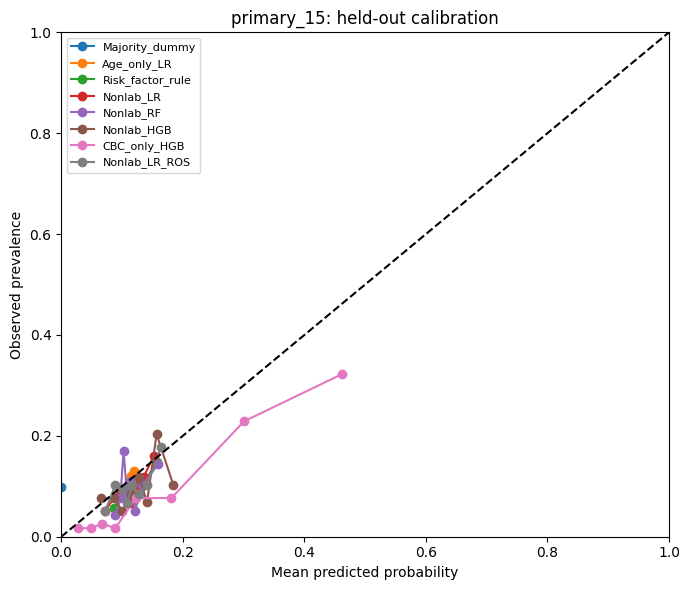

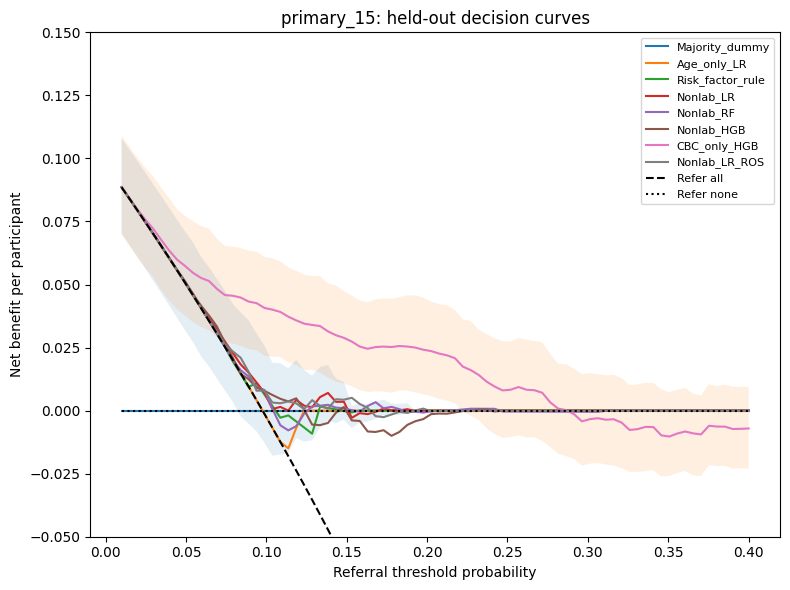

Development-selected non-lab model: Nonlab_LR
Held-out false negatives: 23
                 variable                    group   n  positives  false_negatives  FN_rate_among_positives  low_score_positives  mean_age  mean_PIR  low_score_cutoff
         diet_recall_days                        2 735         69               17                 0.246377                   15 32.131973  2.504335          0.105966
         diet_recall_days                        0  83          7                0                 0.000000                    0 33.265060  2.242182          0.105966
         diet_recall_days                        1 124         16                6                 0.375000                    6 30.870968  2.470101          0.105966
                age_group                    20–29 377         39               14                 0.358974                   13 24.575597  2.335166          0.105966
                age_group                    30–39 379         34                6        

,group_variable,group,model,n,positives,prevalence,AUROC,PR_AUC_AP,precision,recall,...,PR_AUC_AP_high,precision_low,precision_high,recall_low,recall_high,F1_low,F1_high,Brier_low,Brier_high,caution
0,race_ethnicity,Other race / multiracial,Nonlab_LR,204,19,0.093137,0.427596,0.092045,0.078740,0.526316,...,0.200357,0.035361,0.127368,0.266579,0.737171,0.064907,0.211768,0.055258,0.116729,Small group: descriptive only
1,race_ethnicity,Other race / multiracial,CBC_only_HGB,204,19,0.093137,0.869417,0.427277,0.165138,0.947368,...,0.634703,0.102557,0.243584,0.823254,1.000000,0.185543,0.389093,0.051822,0.089736,Small group: descriptive only
2,race_ethnicity,Non-Hispanic Black,Nonlab_LR,185,17,0.091892,0.637955,0.198182,0.111111,0.941176,...,0.378091,0.059562,0.166723,0.777778,1.000000,0.111036,0.284331,0.054602,0.113492,Small group: descriptive only
3,race_ethnicity,Non-Hispanic Black,CBC_only_HGB,185,17,0.091892,0.779762,0.362212,0.120567,1.000000,...,0.587822,0.069918,0.176056,1.000000,1.000000,0.130698,0.299401,0.080850,0.114985,Small group: descriptive only
4,race_ethnicity,Non-Hispanic White,Nonlab_LR,312,23,0.073718,0.577253,0.115179,0.085890,0.608696,...,0.285965,0.046743,0.126735,0.388782,0.807870,0.084635,0.218404,0.046053,0.088705,
5,race_ethnicity,Non-Hispanic White,CBC_only_HGB,312,23,0.073718,0.845645,0.292496,0.149660,0.956522,...,0.447272,0.091533,0.201319,0.857143,1.000000,0.166638,0.335163,0.044772,0.078763,
6,race_ethnicity,Other Hispanic,Nonlab_LR,106,14,0.132075,0.630435,0.212793,0.132530,0.785714,...,0.394833,0.063215,0.205247,0.500000,1.000000,0.110993,0.330352,0.072661,0.160026,Small group: descriptive only
7,race_ethnicity,Other Hispanic,CBC_only_HGB,106,14,0.132075,0.843944,0.682190,0.214286,0.857143,...,0.856270,0.120503,0.345061,0.625000,1.000000,0.196664,0.500187,0.054028,0.118359,Small group: descriptive only
8,race_ethnicity,Mexican American,Nonlab_LR,135,19,0.140741,0.591198,0.193203,0.163636,0.947368,...,0.368309,0.094003,0.232892,0.809286,1.000000,0.171809,0.372573,0.076247,0.166289,Small group: descriptive only
9,race_ethnicity,Mexican American,CBC_only_HGB,135,19,0.140741,0.765426,0.452302,0.227273,0.789474,...,0.665415,0.130400,0.338033,0.583224,0.961000,0.222024,0.476374,0.071727,0.141652,Small group: descriptive only


sensitivity_30 | held-out AP no-skill reference: 0.32908704883227174


,model,policy,n,positives,prevalence,AUROC,PR_AUC_AP,precision,recall,F1,...,recall_low,recall_high,F1_low,F1_high,Brier_low,Brier_high,calibration_intercept,calibration_slope,calibration_in_large,calibration_status
0,Majority_dummy,default_0.5,942,310,0.329087,0.500000,0.329087,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.300425,0.357749,NaN,NaN,NaN,unidentified
1,Majority_dummy,development_screening,942,310,0.329087,0.500000,0.329087,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.300425,0.357749,NaN,NaN,NaN,unidentified
2,Age_only_LR,default_0.5,942,310,0.329087,0.497152,0.322169,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.211870,0.230444,-0.856530,-0.216415,-0.046424,estimated
3,Age_only_LR,development_screening,942,310,0.329087,0.497152,0.322169,0.332589,0.961290,0.494196,...,0.938744,0.981629,0.458811,0.526306,0.211870,0.230444,-0.856530,-0.216415,-0.046424,estimated
4,Risk_factor_rule,default_0.5,942,310,0.329087,0.556309,0.359951,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.210268,0.228474,0.741524,2.212044,-0.053327,estimated
5,Risk_factor_rule,development_screening,942,310,0.329087,0.556309,0.359951,0.338854,0.858065,0.485845,...,0.817385,0.894001,0.446802,0.519984,0.210268,0.228474,0.741524,2.212044,-0.053327,estimated
6,Nonlab_LR,default_0.5,942,310,0.329087,0.597172,0.415989,0.454545,0.016129,0.031153,...,0.003210,0.031568,0.006289,0.059978,0.205802,0.227119,-0.203153,0.718416,-0.014119,estimated
7,Nonlab_LR,development_screening,942,310,0.329087,0.597172,0.415989,0.371901,0.725806,0.491803,...,0.673043,0.772581,0.449234,0.529349,0.205802,0.227119,-0.203153,0.718416,-0.014119,estimated
8,Nonlab_RF,default_0.5,942,310,0.329087,0.600148,0.408008,0.400000,0.012903,0.025000,...,0.003115,0.025492,0.006098,0.048797,0.204818,0.225676,-0.084404,0.909253,-0.024495,estimated
9,Nonlab_RF,development_screening,942,310,0.329087,0.600148,0.408008,0.369458,0.725806,0.489663,...,0.681455,0.776270,0.450703,0.524771,0.204818,0.225676,-0.084404,0.909253,-0.024495,estimated


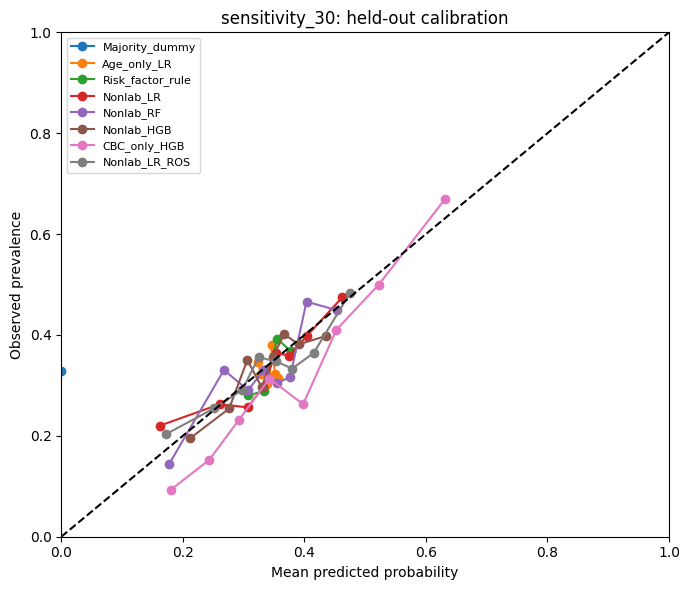

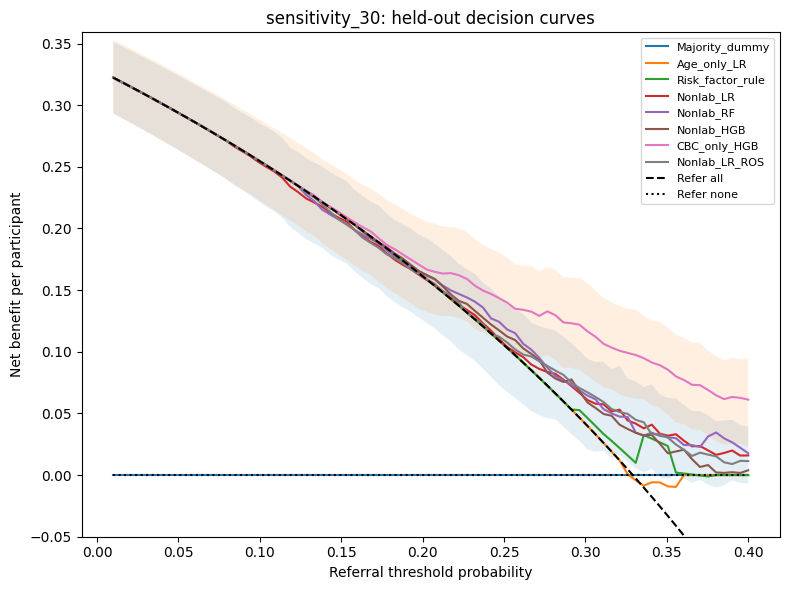

Development-selected non-lab model: Nonlab_LR
Held-out false negatives: 85
                 variable                    group   n  positives  false_negatives  FN_rate_among_positives  low_score_positives  mean_age  mean_PIR  low_score_cutoff
         diet_recall_days                        2 735        244               74                 0.303279                   64 32.131973  2.504335          0.311755
         diet_recall_days                        0  83         27                1                 0.037037                    1 33.265060  2.242182          0.311755
         diet_recall_days                        1 124         39               10                 0.256410                    9 30.870968  2.470101          0.311755
                age_group                    20–29 377        128               31                 0.242188                   25 24.575597  2.335166          0.311755
                age_group                    30–39 379        122               30        

,group_variable,group,model,n,positives,prevalence,AUROC,PR_AUC_AP,precision,recall,...,PR_AUC_AP_high,precision_low,precision_high,recall_low,recall_high,F1_low,F1_high,Brier_low,Brier_high,caution
0,race_ethnicity,Other race / multiracial,Nonlab_LR,204,60,0.294118,0.540046,0.316547,0.339450,0.616667,...,0.405346,0.242669,0.420283,0.474431,0.737823,0.329346,0.535519,0.190975,0.231496,
1,race_ethnicity,Other race / multiracial,CBC_only_HGB,204,60,0.294118,0.760301,0.541101,0.369128,0.916667,...,0.678896,0.300000,0.440311,0.839286,0.980061,0.449918,0.601102,0.164056,0.198652,
2,race_ethnicity,Non-Hispanic Black,Nonlab_LR,185,60,0.324324,0.557867,0.419896,0.325203,0.666667,...,0.562234,0.250000,0.409594,0.542147,0.777917,0.351470,0.527025,0.194702,0.237505,
3,race_ethnicity,Non-Hispanic Black,CBC_only_HGB,185,60,0.324324,0.694000,0.567857,0.349693,0.950000,...,0.698082,0.286390,0.411070,0.894690,1.000000,0.439088,0.577615,0.189473,0.228069,
4,race_ethnicity,Non-Hispanic White,Nonlab_LR,312,90,0.288462,0.577127,0.384990,0.333333,0.600000,...,0.500545,0.266124,0.398934,0.516762,0.700114,0.361936,0.492364,0.180190,0.223488,
5,race_ethnicity,Non-Hispanic White,CBC_only_HGB,312,90,0.288462,0.747347,0.572343,0.379310,0.855556,...,0.686871,0.307317,0.445066,0.784933,0.931054,0.451533,0.588629,0.160910,0.193593,
6,race_ethnicity,Other Hispanic,Nonlab_LR,106,44,0.415094,0.578812,0.463224,0.440860,0.931818,...,0.623120,0.347358,0.548414,0.868409,1.000000,0.507595,0.698019,0.215542,0.258162,
7,race_ethnicity,Other Hispanic,CBC_only_HGB,106,44,0.415094,0.740836,0.729439,0.493827,0.909091,...,0.828725,0.394679,0.581242,0.804628,0.977778,0.537703,0.715396,0.174545,0.241208,
8,race_ethnicity,Mexican American,Nonlab_LR,135,56,0.414815,0.595841,0.541940,0.449153,0.946429,...,0.656386,0.358958,0.530494,0.875000,1.000000,0.521726,0.681564,0.212743,0.255254,
9,race_ethnicity,Mexican American,CBC_only_HGB,135,56,0.414815,0.693264,0.640866,0.476636,0.910714,...,0.768706,0.380942,0.571499,0.824483,0.981826,0.535925,0.714406,0.191929,0.239735,


,target,nonlab_model,metric,CBC_minus_nonlab,low,high
0,primary_15,Nonlab_LR,AUROC,0.223964,0.154332,0.300953
1,primary_15,Nonlab_LR,PR_AUC_AP,0.239815,0.153931,0.339430
2,primary_15,Nonlab_RF,AUROC,0.269437,0.198561,0.344161
3,primary_15,Nonlab_RF,PR_AUC_AP,0.249304,0.168461,0.348470
4,primary_15,Nonlab_HGB,AUROC,0.236957,0.158708,0.317000
5,primary_15,Nonlab_HGB,PR_AUC_AP,0.256547,0.172869,0.359698
6,sensitivity_30,Nonlab_LR,AUROC,0.128348,0.073266,0.185130
7,sensitivity_30,Nonlab_LR,PR_AUC_AP,0.165088,0.093824,0.224092
8,sensitivity_30,Nonlab_RF,AUROC,0.125373,0.067276,0.177071
9,sensitivity_30,Nonlab_RF,PR_AUC_AP,0.173070,0.108733,0.227978


In [ ]:
heldout_results = {}
paired_results = []
subgroup_results, failure_results = {}, {}
for label, developed in development_results.items():
    evaluated = evaluate_frozen(heldout_data, developed, categorical_features_final, CONFIG)
    heldout_results[label] = evaluated
    save_analysis(developed, evaluated, label)
    print(label, "| held-out AP no-skill reference:", evaluated["y"].mean())
    display(evaluated["table"])
    for name in ["Nonlab_LR", "Nonlab_RF", "Nonlab_HGB", developed["winner"]]:
        if any(r["target"] == label and r["nonlab_model"] == name for r in paired_results):
            continue
        difference = paired_discrimination(
            evaluated["y"], evaluated["probabilities"]["CBC_only_HGB"],
            evaluated["probabilities"][name], CONFIG["bootstrap"])
        for row in difference.to_dict("records"):
            paired_results.append({"target": label, "nonlab_model": name, **row})
    diagnostic_plots(evaluated, label, CONFIG)
    subgroup_results[label], failure_results[label] = subgroup_and_failure(
        heldout_data, developed, evaluated, label, CONFIG)
    display(subgroup_results[label])
paired_comparison = pd.DataFrame(paired_results)
paired_comparison.to_csv(RESULTS_DIR / "paired_CBC_minus_nonlab.csv", index=False)
display(paired_comparison)

## F. Ferritin-cutoff sensitivity and failure analysis interpretation

The table below places identical model families beside each other across the two target definitions. A higher AP at <30 µg/L can partly reflect higher prevalence; compare AP minus prevalence and AP/prevalence as descriptive context, and inspect AUROC, calibration, recall, net benefit, and paired CBC-minus-nonlab differences. AP lift is not a complete prevalence-invariant comparison. The development-selected winner may change by target; report this rather than choosing a new winner from held-out scores.

Failure tables show false-negative rates **among deficient participants in each group**, not merely raw missed-case counts. They also identify deficient cases below the development-score first quartile. Investigate recall-day count, age, individual reproductive-history missingness, supplement use, race/ethnicity, and PIR. Missing years since birth can be structurally appropriate for never-pregnant/nulliparous participants; it is not automatically a data-quality failure. `DSD010` measures any supplement use, not iron-specific supplementation. Race is a social/demographic variable; predictive patterns do not demonstrate biological causation.

Results must be summarized after execution: which groups have consistently higher miss rates, with denominators and uncertainty? Do not interpret tiny groups, overlapping intervals, or exploratory comparisons as established disparities. The participant file is public NHANES data but should still be handled responsibly.

In [ ]:
sensitivity_rows = []
for label, result in heldout_results.items():
    table = result["table"].query("policy == 'development_screening'").copy()
    table["target"] = label
    table["AP_minus_prevalence"] = table.PR_AUC_AP - table.prevalence
    table["AP_lift"] = table.PR_AUC_AP / table.prevalence
    table["development_selected"] = table.model.eq(result["winner"])
    sensitivity_rows.append(table)
cutoff_comparison = pd.concat(sensitivity_rows, ignore_index=True)
cutoff_comparison.to_csv(RESULTS_DIR / "ferritin_cutoff_comparison.csv", index=False)
display(cutoff_comparison[["target", "model", "development_selected", "prevalence",
                           "AUROC", "PR_AUC_AP", "AP_minus_prevalence", "AP_lift",
                           "recall", "precision", "F1", "Brier",
                           "calibration_intercept", "calibration_slope"]])

,target,model,development_selected,prevalence,AUROC,PR_AUC_AP,AP_minus_prevalence,AP_lift,recall,precision,F1,Brier,calibration_intercept,calibration_slope
0,primary_15,Majority_dummy,False,0.097665,0.500000,0.097665,0.000000,1.000000,0.000000,0.000000,0.000000,0.097665,NaN,NaN
1,primary_15,Age_only_LR,False,0.097665,0.495754,0.098839,0.001174,1.012023,0.576087,0.093805,0.161339,0.088507,-3.022658,-0.394918
2,primary_15,Risk_factor_rule,False,0.097665,0.553868,0.112599,0.014935,1.152918,0.902174,0.105732,0.189282,0.088218,-0.097924,1.058267
3,primary_15,Nonlab_LR,True,0.097665,0.592506,0.138155,0.040490,1.414583,0.750000,0.110048,0.191933,0.087632,0.646958,1.415784
4,primary_15,Nonlab_RF,False,0.097665,0.547033,0.128665,0.031001,1.317419,0.554348,0.100592,0.170284,0.088076,-0.215799,0.987232
5,primary_15,Nonlab_HGB,False,0.097665,0.579514,0.121423,0.023758,1.243265,0.706522,0.116071,0.199387,0.088443,-0.725005,0.756545
6,primary_15,CBC_only_HGB,False,0.097665,0.816471,0.377969,0.280305,3.870078,0.913043,0.161850,0.274959,0.079641,-0.415062,1.234623
7,primary_15,Nonlab_LR_ROS,False,0.097665,0.588414,0.141193,0.043529,1.445696,0.684783,0.111307,0.191489,0.087578,0.135978,1.158486
8,sensitivity_30,Majority_dummy,False,0.329087,0.500000,0.329087,0.000000,1.000000,0.000000,0.000000,0.000000,0.329087,NaN,NaN
9,sensitivity_30,Age_only_LR,False,0.329087,0.497152,0.322169,-0.006918,0.978979,0.961290,0.332589,0.494196,0.221062,-0.856530,-0.216415


In [ ]:
# NEW CELL
referral_rows = []

for label in ["primary_15", "sensitivity_30"]:

    result = heldout_results[label]
    selected_nonlab = result["winner"]

    for model in [selected_nonlab, "CBC_only_HGB"]:

        row = result["table"][
            (result["table"]["model"] == model) &
            (result["table"]["policy"] == "development_screening")
        ].iloc[0]

        referrals = int(row["TP"] + row["FP"])
        true_positives = int(row["TP"])
        false_positives = int(row["FP"])
        missed = int(row["FN"])

        referral_rows.append({
            "target": label,
            "model": model,
            "n": int(row["n"]),
            "referrals": referrals,
            "referral_rate": referrals / row["n"],
            "true_positives_found": true_positives,
            "false_positive_referrals": false_positives,
            "missed_cases": missed,
            "recall": row["recall"],
            "precision": row["precision"],
            "referrals_per_true_positive":
                referrals / true_positives if true_positives > 0 else np.nan
        })

referral_burden = pd.DataFrame(referral_rows)

display(referral_burden)

referral_burden.to_csv(
    RESULTS_DIR / "referral_burden_summary.csv",
    index=False
)

,target,model,n,referrals,referral_rate,true_positives_found,false_positive_referrals,missed_cases,recall,precision,referrals_per_true_positive
0,primary_15,Nonlab_LR,942,627,0.665605,69,558,23,0.750000,0.110048,9.086957
1,primary_15,CBC_only_HGB,942,519,0.550955,84,435,8,0.913043,0.161850,6.178571
2,sensitivity_30,Nonlab_LR,942,605,0.642251,225,380,85,0.725806,0.371901,2.688889
3,sensitivity_30,CBC_only_HGB,942,703,0.746285,280,423,30,0.903226,0.398293,2.510714


To supplement traditional model-performance metrics, we evaluated the practical referral burden associated with the development-selected screening thresholds. For the primary ferritin <15 µg/L outcome, the non-lab logistic regression model referred 627 of 942 participants (66.6%) and identified 69 of 92 iron-deficient cases, corresponding to approximately 9.1 referrals per true positive detected. The CBC benchmark referred fewer participants (519; 55.1%) while identifying 84 of 92 deficient cases, requiring approximately 6.2 referrals per true positive. For the ferritin <30 µg/L sensitivity outcome, the non-lab model required approximately 2.7 referrals per detected case compared with 2.5 for the CBC model. These results provide an operational perspective on the trade-off between identifying deficient participants and generating unnecessary referrals.

## F.1. Which non-lab predictors matter? Permutation importance

**Question:** When we scramble one predictor at a time, how much worse does the already-trained non-lab model get at identifying iron deficiency without anemia?

This uses the **development-selected model for ferritin <15 µg/L** and evaluates it on the same 2017–2020 later-cycle sample. We randomly shuffle each of the **27 original non-lab columns 20 times**, keeping all other columns and the trained model unchanged. The importance score is the **drop in average precision (AP)** from the original predictions. A larger positive drop suggests that feature contributes to prediction; a score near zero means shuffling had little effect in this analysis.

This is **exploratory interpretation**, not causal evidence. Correlated variables can share importance, and shuffling can create combinations of values that would not naturally occur. Do not use the later-cycle importance ranking to reselect predictors or tune the model and then call the same cycle an independent test. The cell saves a ranked CSV and a top-predictor plot to `cis631_results/`.

Selected non-lab model: Nonlab_LR
Later-cycle participants: 942
Baseline average precision: 0.1382
Higher positive AP drop means greater model reliance on that predictor.


,predictor,mean_AP_drop,SD_across_20_shuffles
0,RHQ031,0.020716,0.006884
1,avg_protein,0.018418,0.006679
2,RIDRETH1,0.015731,0.005856
3,years_since_last_birth,0.014923,0.010383
4,num_live_birth_deliveries,0.010281,0.010634
5,avg_heme_food,0.007026,0.008889
6,PAQ665,0.004713,0.002366
7,num_pregnancies,0.004324,0.008368
8,DSDCOUNT,0.004034,0.002349
9,RHD280,0.003495,0.002889


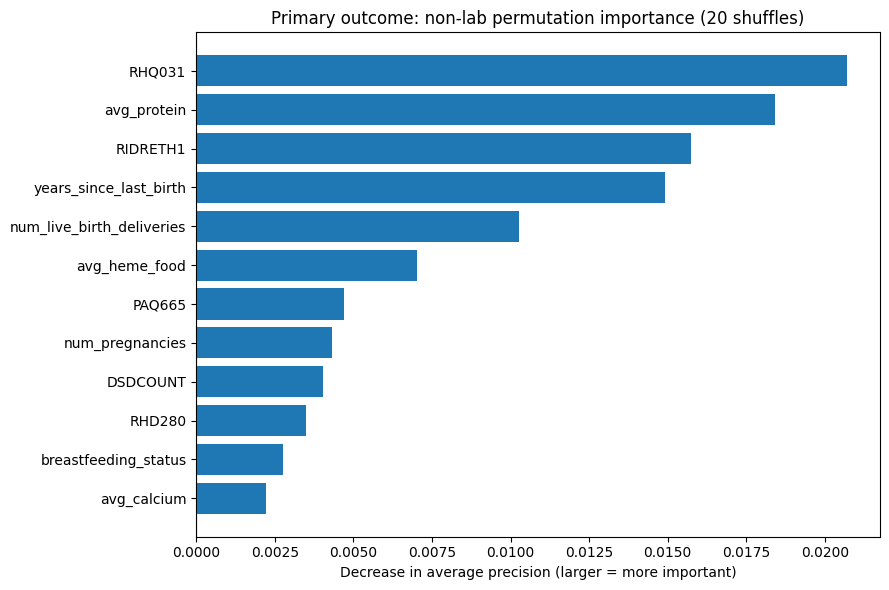

In [ ]:
# Permutation importance of the frozen, development-selected non-lab model.
# This is interpretation only: no new fitting, feature selection, or threshold changes.
from sklearn.inspection import permutation_importance

importance_label = "primary_15"
developed = development_results[importance_label]
selected_name = developed["winner"]
selected_model = developed["models"][selected_name]
assert selected_model["columns"] == final_features, (
    "The development winner is not the full 27-feature non-lab model. "
    "Inspect model selection before interpreting these 27 predictors."
)

X_importance = prepare_X(
    heldout_data, selected_model["columns"], categorical_features_final
)
y_importance = heldout_data[developed["outcome"]].to_numpy(dtype=int)
original_probabilities = selected_model["estimator"].predict_proba(X_importance)[:, 1]
baseline_ap = average_precision_score(y_importance, original_probabilities)

# Check that we are explaining exactly the model and predictions evaluated above.
assert np.allclose(
    original_probabilities,
    heldout_results[importance_label]["probabilities"][selected_name],
), "The fitted model or evaluation sample no longer matches the frozen analysis."

permuted = permutation_importance(
    selected_model["estimator"], X_importance, y_importance,
    scoring="average_precision", n_repeats=20, random_state=SEED, n_jobs=1,
)
importance_table = pd.DataFrame({
    "predictor": X_importance.columns,
    "mean_AP_drop": permuted.importances_mean,
    "SD_across_20_shuffles": permuted.importances_std,
}).sort_values("mean_AP_drop", ascending=False).reset_index(drop=True)
importance_table.to_csv(
    RESULTS_DIR / "primary_15_nonlab_permutation_importance.csv", index=False
)

print(f"Selected non-lab model: {selected_name}")
print(f"Later-cycle participants: {len(y_importance)}")
print(f"Baseline average precision: {baseline_ap:.4f}")
print("Higher positive AP drop means greater model reliance on that predictor.")
display(importance_table.head(12))

# Plot the leading predictors, preserving their original (pre-one-hot) names.
top_predictors = importance_table.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_predictors["predictor"], top_predictors["mean_AP_drop"])
ax.axvline(0, color="gray", linewidth=0.8)
ax.set_xlabel("Decrease in average precision (larger = more important)")
ax.set_title("Primary outcome: non-lab permutation importance (20 shuffles)")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "primary_15_nonlab_permutation_importance.png", dpi=160)
plt.show()


## G. NHANES survey design: weighted descriptive estimates

| Estimate | 2009–2010 and 2015–2016 | 2017–March 2020 |
|---|---|---|
| Ferritin-defined prevalence; age/BMI/PIR | `WTMEC2YR` | `WTMECPRP` |
| First-day dietary iron/calories | `WTDRD1` | `WTDRD1PP` |
| Two-completed-day averages | `WTDR2D` | `WTDR2DPP` |
| Design variance | `SDMVSTRA`, `SDMVPSU` | `SDMVSTRA`, `SDMVPSU` |

The cohort includes zero-, one-, and two-recall participants, so ferritin prevalence uses MEC weights; requiring dietary weights would silently change its denominator. Official two-day weights are used only for two-recall descriptive domains. The mixed available-day average has no single official dietary weight that covers every retained participant: no nationally representative dietary mean is claimed for that mixed average. Day-1 estimates and two-day estimates describe different responding domains.

The function keeps the complete demographic design frame and computes domain-ratio Taylor-linearized variance from PSU totals, with t-based intervals and logit intervals for nondegenerate prevalence. Cycle and design identifiers are nested. Official weights correct sampling and component response, **not automatically the additional missing-ferritin/CRP exclusions**; weighted results remain conditional on the observed eligible domain, and differential item nonresponse may bias them.

For a pooled descriptive average of these **included noncontiguous periods**, multiply 2009–2010 and 2015–2016 weights by 2/7.2 and the special 2017–March 2020 weights by 3.2/7.2. This duration-weighted average does not estimate uninterrupted 2009–2020 prevalence; present cycle-specific estimates first and acknowledge secular change. Do not divide all three releases by 3, and do not add 2017–2018 separately to its overlapping pre-pandemic release. The CDC tutorial explicitly explains the 3.2-year scaling.

**Models remain unweighted.** Balanced class weights and oversampling are not NHANES sampling weights. Performance estimates and participant-bootstrap intervals therefore describe this analytical sample; they must not be presented as survey-weighted U.S. population screening performance. A future design-aware performance analysis and weighted training sensitivity analysis would strengthen generalizability.

Sources: [CDC weighting tutorial](https://wwwn.cdc.gov/nchs/nhanes/tutorials/weighting.aspx), [pre-pandemic dietary documentation](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/P_DR1TOT.htm), [2009 ferritin exam-weight guidance](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2009/DataFiles/FERTIN_F.htm), [pre-pandemic ferritin missing-biospecimen guidance](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/P_FERTIN.htm).

In [ ]:
metadata = survey_metadata(
    {"2009-2010": demo09, "2015-2016": demo15, "2017-2020": demo},
    {"2009-2010": diet09, "2015-2016": diet15, "2017-2020": diet},
    {"2009-2010": diet2_09, "2015-2016": diet2_15, "2017-2020": diet2_17},
)
weighted_estimates, survey_frame = weighted_descriptions(modeling_dataset, metadata)
display(weighted_estimates)
print("Weighted prevalence estimates are proportions; multiply by 100 for percentages.")

,period,variable,weight,domain,n,estimate,SE,low,high,design_df
0,2009-2010,iron_deficient,w_mec,eligible cohort,793,0.118789,0.013734,0.092618,0.151124,16
1,2009-2010,iron_deficient_30,w_mec,eligible cohort,793,0.331684,0.019222,0.292265,0.373612,16
2,2009-2010,RIDAGEYR,w_mec,eligible cohort,793,32.322551,0.400737,31.473027,33.172075,16
3,2009-2010,INDFMPIR,w_mec,eligible cohort,733,2.733665,0.079880,2.564327,2.903002,16
4,2009-2010,BMXBMI,w_mec,eligible cohort,791,25.831192,0.269748,25.259351,26.403033,16
5,2009-2010,DR1TIRON,w_day1,"eligible, first-day responders",760,13.593911,0.361302,12.827985,14.359837,16
6,2009-2010,DR1TKCAL,w_day1,"eligible, first-day responders",760,1843.655376,25.463888,1789.674344,1897.636407,16
7,2009-2010,avg_iron,w_day2,"eligible, two completed recalls",669,13.527006,0.258239,12.979563,14.074448,16
8,2009-2010,avg_calories,w_day2,"eligible, two completed recalls",669,1789.690751,16.166505,1755.419291,1823.962211,16
9,2009-2010,avg_heme_food,w_day2,"eligible, two completed recalls",669,3.905969,0.068649,3.760440,4.051498,16


Weighted prevalence estimates are proportions; multiply by 100 for percentages.


## H. Related work and outcome-definition evidence

### Lab/CBC-based prediction

Efros et al. (2025) studied IDWA using routinely collected electronic records, including hematologic predictors. Their work establishes a relevant predictive benchmark, but a blood-derived feature cannot serve a questionnaire-only referral pathway. Differences in ferritin thresholds and care-seeking populations also prevent direct comparison of headline AUROCs with our cohort. [Study](https://bmjopen.bmj.com/content/15/8/e097016); DOI: 10.1136/bmjopen-2024-097016.

Palika et al. (2026) used CBC indices to predict inflammation-adjusted iron deficiency **anemia** in women, including NHANES development and an Indian validation dataset. It supports the predictive information available in CBC, but its target includes anemia, whereas our cohort excludes anemia. Performance in IDA cannot establish performance in IDWA. [Primary article record](https://pubmed.ncbi.nlm.nih.gov/42165722/); DOI: 10.25259/IJMR_1500_2025.

**Our distinction:** We evaluate the practical cost in discrimination of avoiding blood-derived predictors by comparing CBC-only and non-lab pipelines within the same eligible participants, cycle split, and ferritin definitions. This is a matched feature-set comparison, not an attempt to reproduce either published model. The CBC benchmark is never part of the main screening matrix.

### Non-lab risk factors and screening

Miller (2014) examined reproductive history and iron status using NHANES. It motivates reproductive variables, while its observational associations do not establish their incremental out-of-sample predictive value. [Article](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0112216); DOI: 10.1371/journal.pone.0112216.

Tawfik et al. (2024) quantified absolute and functional deficiency in U.S. adults using the pre-pandemic NHANES release, documenting substantial deficiency even in clinically restricted groups. It motivates population screening research; differences in target definition and eligibility make its prevalence estimates unsuitable as expected counts for this cohort. [Article](https://pmc.ncbi.nlm.nih.gov/articles/PMC11423176/); DOI: 10.1001/jamanetworkopen.2024.33126.

Vinge et al. (2026) developed IRON-5 from diet, menstrual symptoms, supplement use, and contraception among Swedish schoolgirls. This is a direct non-lab screening comparator, so **do not claim that no questionnaire-based iron-deficiency models exist**. Its post-hoc development, younger setting, inclusion of deficiency irrespective of anemia, and need for further validation limit transfer to this study. [Article](https://pmc.ncbi.nlm.nih.gov/articles/PMC13047845/); DOI: 10.1080/02813432.2026.2649329.

**Our distinction:** We evaluate adults aged 20–44 without anemia using NHANES dietary recalls and harmonized reproductive/demographic variables, with a later-cycle assessment, calibration, subgroup analysis, and decision curves. NHANES does not measure all IRON-5 menstrual/contraceptive inputs in our final list; our four-flag baseline does not reproduce IRON-5. Missing menstrual blood-loss severity is a plausible reason for missed cases, not an established finding before analysis.

### Ferritin, inflammation, anemia, and reporting

| Source | Role and interpretation |
|---|---|
| [WHO ferritin guideline (2020)](https://www.who.int/publications/i/item/9789240000124) | Conventional <15 µg/L healthy-adult threshold; inflammation complicates interpretation. [WHO executive summary](https://www.ncbi.nlm.nih.gov/books/NBK569877/) describes an exclusion approach using CRP >5 mg/L and/or AGP >1 g/L. CRP-only exclusion does not capture every inflammatory state. |
| [Mei et al., Lancet Haematology (2021)](https://stacks.cdc.gov/view/cdc/115718) | NHANES physiological indicators suggest a threshold around 25 µg/L in nonpregnant women; motivates a higher-threshold sensitivity analysis. DOI: 10.1016/S2352-3026(21)00168-X. |
| [Addo et al., Blood Advances (2022)](https://ashpublications.org/bloodadvances/article/6/12/3661/484681/Physiologically-based-serum-ferritin-thresholds) | Female-donor physiological thresholds also support ~25 µg/L. Our <30 sensitivity target is a pragmatic alternative, not the exact threshold identified by these papers. |
| [WHO hemoglobin guideline (2024)](https://www.who.int/publications/i/item/9789240088542) | Nonpregnant adult-woman anemia cutoff 120 g/L (12 g/dL); document units and smoking adjustment. Preserve the notebook's existing adjustment and report its exact quantities. |
| [Collins et al., TRIPOD+AI (2024)](https://www.bmj.com/content/385/bmj-2023-078378) | Reporting guidance for regression and ML prediction models; not a guarantee that a design is unbiased. DOI: 10.1136/bmj-2023-078378. |
| [CDC CBC documentation](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/P_CBC.htm) | CBC names, units, instruments and analytic considerations; inspect assay/instrument changes across cycles. |

These sources were checked during notebook preparation (September 30, 2026, America/Chicago). Verify full citation formatting against your course's required style before submission. Foundational guidance and Miller are intentionally retained despite their age; recent prediction, epidemiology, threshold, and reporting papers complement them.

## I. Validity, ethics, and TRIPOD+AI reporting checklist

| Reporting area | What this project must state |
|---|---|
| Participants and flow | Public NHANES cycles, existing age/pregnancy/CRP/hemoglobin/ferritin rules, exclusions and denominators; use original preparation outputs for flow counts |
| Predictors and target | All 27 codes/derived definitions; recall-day averaging and FPED food proxies; target ferritin <15 and sensitivity <30; no ferritin/CRP/CBC leakage |
| Missing values | Per-variable/cycle missingness; median + missing-indicator numeric pipeline; categorical Missing level; distinguish structural reproductive skip patterns |
| Internal validity | Self-reported diet/activity and brief recalls can mismeasure usual intake; missingness can encode questionnaire/cycle artifacts; CRP-only exclusion may leave residual ferritin inflammation bias |
| Construct validity | Ferritin cutoffs classify a continuous physiological state; <15 and <30 address different case definitions; dietary intake is not absorbed iron |
| Validation history | Later-cycle split is retrospective temporal validation; earlier notebook exploration already used later-cycle data, so report possible development contamination |
| Selection and calibration | Nested CV and AP tuning, weight/resampling candidates, sigmoid calibration, fixed ≥80% development recall target; held-out calibration diagnoses without refitting |
| Uncertainty | Conditional participant bootstrap for model metrics; domain survey variance for weighted means/prevalence; repeated-CV SD is not a CI |
| External validity | U.S. civilian noninstitutionalized population, ages 20–44, nonpregnant and nonanemic with measured low CRP; no automatic transfer to pregnancy, anemia, older ages, other countries or clinical referrals |
| Fairness | Race/PIR subgroup n/events/intervals; no causal or biological interpretation; small-group findings remain exploratory |
| Ethics | Referral aid for confirmatory assessment, not a diagnosis or justification for unsupervised supplementation; false negatives remain possible |
| Reproducibility | Preserve final objects, variable dictionary, random seeds, version manifest, hashes, candidate grids, fold metrics, OOF predictions, thresholds and exported tables |

**Specific cohort rules already in the notebook:** Pregnancy status `RIDEXPRG == 2`; ages 20–44; observed `CRP_mgL <= 5` (2009 `LBXCRP` mg/dL multiplied by 10; later `LBXHSCRP` mg/L); observed ferritin; adjusted hemoglobin ≥12 g/dL. Current-smoking subtraction is 0.3 g/dL when quantity is unknown or <10 cigarettes/day, 0.5 for 10–19, and 0.6 for ≥20. Missing quantity uses the notebook's existing fallback, which should be described as an assumption. Public geographic information cannot support a precise altitude adjustment in this continuation.

**Deployment constraint:** Although predictor inputs avoid a blood draw, this research cohort was selected using hemoglobin and CRP. A real pre-blood-draw setting cannot necessarily establish those eligibility conditions. The analysis therefore estimates discrimination within a retrospectively lab-defined domain; it does not establish performance in all women presenting for screening.

**Interpretation after execution:** Report the development-selected non-lab model first, then baselines and CBC benchmark. Explain the paired discrimination difference with its CI, how prevalence changes AP, whether calibration supports probability interpretation, where net benefit exceeds both comparison policies, and which deficient groups are missed. Do not claim a material cutoff change from a different AP alone. No project conclusions about performance are justified before running these cells.

In [ ]:
import joblib
import shutil

handoff_hash_after = hashlib.sha256(
    pd.util.hash_pandas_object(modeling_dataset, index=True).values.tobytes()
).hexdigest()
assert handoff_hash_after == handoff_hash_before, "The original final dataframe changed."
manifest = {
    "seed": SEED, "config": CONFIG,
    "python": platform.python_version(), "sklearn": sklearn.__version__,
    "pandas": pd.__version__, "numpy": np.__version__, "scipy": scipy.__version__,
    "numeric_features": numeric_features_final,
    "categorical_features": categorical_features_final, "final_features": final_features,
    "cbc_features_and_units": {c: CBC_UNITS[c] for c in cbc_features},
    "cohort_hash": handoff_hash_after, "cohort_n": len(modeling_dataset),
    "ML_survey_weighted": False,
    "development_cycles": ["2009-2010", "2015-2016"],
    "heldout_cycle": "2017-2020", "AP_definition": "average_precision_score",
    "weighted_pool": "Included-period average; 2/7.2, 2/7.2, 3.2/7.2",
}
(RESULTS_DIR / "reproducibility_manifest.json").write_text(json.dumps(manifest, indent=2))
for label, developed in development_results.items():
    # Reload only trusted files and define the helper classes before loading.
    joblib.dump({name: rec["estimator"] for name, rec in developed["models"].items()},
                RESULTS_DIR / f"{label}_fitted_models.joblib")
pd.DataFrame({"feature": final_features,
              "type": ["numeric"] * len(numeric_features_final)
                      + ["categorical"] * len(categorical_features_final)}).to_csv(
    RESULTS_DIR / "final_predictor_dictionary.csv", index=False)
archive = shutil.make_archive("cis631_results", "zip", RESULTS_DIR)
print("Saved outputs:", sorted(p.name for p in RESULTS_DIR.iterdir()))
print("Archive:", archive)

Saved outputs: ['cbc_missingness_by_cycle.csv', 'cbc_predictor_units.csv', 'ferritin_cutoff_comparison.csv', 'final_predictor_dictionary.csv', 'paired_CBC_minus_nonlab.csv', 'primary_15_calibration.png', 'primary_15_calibration_bins.csv', 'primary_15_decision_curve.csv', 'primary_15_decision_curve.png', 'primary_15_development_cv.csv', 'primary_15_development_oof_probabilities.csv', 'primary_15_development_tuning.csv', 'primary_15_failure_patterns.csv', 'primary_15_fitted_models.joblib', 'primary_15_frozen_specification.json', 'primary_15_heldout_metrics.csv', 'primary_15_heldout_predictions.csv', 'primary_15_missed_participants.csv', 'primary_15_nested_fold_metrics.csv', 'primary_15_nonlab_permutation_importance.csv', 'primary_15_nonlab_permutation_importance.png', 'primary_15_pretest_choices.json', 'primary_15_subgroups.csv', 'referral_burden_summary.csv', 'reproducibility_manifest.json', 'sensitivity_30_calibration.png', 'sensitivity_30_calibration_bins.csv', 'sensitivity_30_decisio

## J. Three additional non-lab models (instructor-requested extension)

This extension compares **Decision Tree, k-nearest neighbors (KNN), and RBF Support Vector Machine (SVM)**. All three use the same **27 non-blood predictors** and the same older-cycle development (1,455) / later-cycle evaluation (942) populations as the original logistic regression, random forest and histogram boosting models.

To keep the supplementary experiment quick, the additional models use **one stratified five-fold outer CV pass** (rather than the original 10 repeats), three-fold inner hyperparameter tuning, and training-only probability calibration. The classification threshold is chosen with **development out-of-fold** predictions to aim for 80% recall. The later-cycle results are then calculated without fitting on the later-cycle sample.

**Interpretation:** These are **exploratory additions**, because earlier later-cycle results have already been examined. Do not relabel the later cycle as untouched external validation or replace the original development-selected logistic regression winner. Evaluate AUROC/AP as well as recall, precision, and false positives. The CSVs and a new ZIP are saved separately.


In [ ]:
# CIS 631: three additional non-lab classifiers (primary ferritin <15 outcome)
# Run after the existing full notebook has created development_data, heldout_data,
# final_features, CONFIG, preprocessing(), develop_models() and evaluate_frozen().
# These are exploratory follow-up analyses; the originally selected LR remains frozen.

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from pathlib import Path
import pandas as pd
import json
import shutil

# Match original predictors, participants, and time/cycle split.
assert len(final_features) == 27
assert len(development_data) == 1455 and len(heldout_data) == 942
assert set(development_data['cycle']) == {'2009-2010', '2015-2016'}
assert set(heldout_data['cycle']) == {'2017-2020'}
assert sum(development_data['iron_deficient']) == 170
assert sum(heldout_data['iron_deficient']) == 92

# The same imputation and one-hot encoding used in the original comparison.
# Scaling matters for KNN and the RBF SVM; a decision tree does not need it.
def additional_nonlab_pipeline(estimator, scale=False):
    return Pipeline([
        ('prep', preprocessing(numeric_features_final,
                               categorical_features_final, scale=scale)),
        ('clf', estimator),
    ])

additional_specs = {
    'Nonlab_DecisionTree': (
        additional_nonlab_pipeline(DecisionTreeClassifier(random_state=SEED)),
        final_features,
        {'clf__max_depth': [3, 6],
         'clf__min_samples_leaf': [10, 20],
         'clf__class_weight': [None, 'balanced']},
        True,
    ),
    'Nonlab_KNN': (
        additional_nonlab_pipeline(KNeighborsClassifier(), scale=True),
        final_features,
        {'clf__n_neighbors': [15, 35],
         'clf__weights': ['uniform', 'distance']},
        True,
    ),
    'Nonlab_SVM_RBF': (
        additional_nonlab_pipeline(
            SVC(kernel='rbf', gamma='scale', random_state=SEED), scale=True
        ),
        final_features,
        {'clf__C': [0.3, 3.0],
         'clf__class_weight': [None, 'balanced']},
        True,
    ),
}

# Original models used 5 folds x 10 repeats. For a time-efficient, clearly
# labeled follow-up, we use 5 folds x 1 repeat and the same inner 3-fold tuning.
# No held-out labels are used for preprocessing, tuning, or threshold choice.
additional_config = {**CONFIG, 'outer_folds': 5, 'outer_repeats': 1,
                     'inner_folds': 3, 'bootstrap': 150, 'n_jobs': 2}

print('Fitting 3 additional models on 1,455 development participants...')
additional_development = develop_models(
    development_data, 'iron_deficient', additional_specs,
    categorical_features_final, additional_config
)
print('Evaluating on 942 later-cycle participants...')
additional_evaluation = evaluate_frozen(
    heldout_data, additional_development,
    categorical_features_final, additional_config
)

# Save new results without overwriting the previously completed comparison.
RESULTS_DIR = Path('cis631_results')
RESULTS_DIR.mkdir(exist_ok=True)
additional_development['cv_table'].to_csv(
    RESULTS_DIR / 'three_additional_models_development_cv.csv', index=False)
additional_evaluation['table'].to_csv(
    RESULTS_DIR / 'three_additional_models_heldout_metrics.csv', index=False)
additional_evaluation['predictions'].to_csv(
    RESULTS_DIR / 'three_additional_models_heldout_predictions.csv', index=False)
pd.DataFrame(additional_development['final_tuning']).to_csv(
    RESULTS_DIR / 'three_additional_models_tuning.csv', index=False)

protocol = {
    'status': 'exploratory model expansion after prior results were inspected',
    'outcome': 'iron_deficient (ferritin <15 ug/L; no anemia)',
    'models': list(additional_specs),
    'development_cycles': ['2009-2010', '2015-2016'],
    'evaluation_cycle': '2017-2020',
    'predictors': 27,
    'outer_cv_folds': 5,
    'outer_cv_repeats': 1,
    'inner_tuning_folds': 3,
    'optimization_metric': 'average_precision',
    'classification_threshold': 'selected on development out-of-fold scores to target 80% recall',
    'original_winner_unchanged': 'Nonlab_LR',
    'note': 'Added after earlier later-cycle results were already inspected; this is not independent external validation.'
}
(RESULTS_DIR / 'three_additional_models_protocol.json').write_text(
    json.dumps(protocol, indent=2))

original = heldout_results['primary_15']['table']
combined = pd.concat([original, additional_evaluation['table']], ignore_index=True)
comparison = combined.loc[combined['policy'].eq('development_screening'), [
    'model', 'AUROC', 'PR_AUC_AP', 'recall', 'precision', 'F1', 'TP', 'FP'
]].copy().sort_values('PR_AUC_AP', ascending=False)
comparison.to_csv(
    RESULTS_DIR / 'all_models_primary_15_comparison.csv', index=False)
print('\nAll models compared using the same 2017-2020 evaluation participants:')
display(comparison.round(3))
print('\nNew files:', sorted(p.name for p in RESULTS_DIR.glob('three_additional_models_*')))
archive = shutil.make_archive('cis631_results_with_three_more_models', 'zip', RESULTS_DIR)
print('Updated results ZIP:', archive)


Fitting 3 additional models on 1,455 development participants...
iron_deficient Nonlab_DecisionTree completed repeats: 1
iron_deficient Nonlab_KNN completed repeats: 1
iron_deficient Nonlab_SVM_RBF completed repeats: 1
Evaluating on 942 later-cycle participants...

All models compared using the same 2017-2020 evaluation participants:


,model,AUROC,PR_AUC_AP,recall,precision,F1,TP,FP
13,CBC_only_HGB,0.816,0.378,0.913,0.162,0.275,84,435
15,Nonlab_LR_ROS,0.588,0.141,0.685,0.111,0.191,63,503
7,Nonlab_LR,0.593,0.138,0.750,0.110,0.192,69,558
9,Nonlab_RF,0.547,0.129,0.554,0.101,0.170,51,456
21,Nonlab_SVM_RBF,0.583,0.124,0.935,0.104,0.188,86,738
11,Nonlab_HGB,0.580,0.121,0.707,0.116,0.199,65,495
19,Nonlab_KNN,0.536,0.116,0.957,0.103,0.187,88,763
5,Risk_factor_rule,0.554,0.113,0.902,0.106,0.189,83,702
17,Nonlab_DecisionTree,0.545,0.111,0.946,0.105,0.189,87,743
3,Age_only_LR,0.496,0.099,0.576,0.094,0.161,53,512



New files: ['three_additional_models_development_cv.csv', 'three_additional_models_heldout_metrics.csv', 'three_additional_models_heldout_predictions.csv', 'three_additional_models_protocol.json', 'three_additional_models_tuning.csv']
Updated results ZIP: /content/cis631_results_with_three_more_models.zip


In [ ]:
from google.colab import files
files.download('/content/cis631_results_with_three_more_models.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>